# [GSE176389](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE176389)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-10-17
> - Modified: 2026-01-03

# 1. Experimental Design

> Tet1 regulates embryonic stem cell differentiation programs and development independent of its catalytic activity.
> - Stephanie Chrysanthou, Qin Tang, Joun Lee, Samuel J Taylor, Yilin Zhao, Ulrich Steidl, Deyou Zheng, Meelad M Dawlaty, The DNA dioxygenase Tet1 regulates H3K27 modification and embryonic stem cell biology independent of its catalytic activity, Nucleic Acids Research, Volume 50, Issue 6, 8 April 2022, Pages 3169–3189, https://doi.org/10.1093/nar/gkac089.
> - WGBS
> - Illumina NextSeq 500, PE100
> - mm10

| Sample | Cell | Source | Strain | Gene | Genotype | Replicate |
| - | - | - | - | - | - | - |
| Tet1 WT | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Wild Type | rep1~2 |
| Tet1 Mut | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Mutant | rep1~2 |
| Tet1 KO | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Knockout | rep1~2 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tet1_GSE176389/10_output_wgbs"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

suppressPackageStartupMessages(library(TxDb.Mmusculus.UCSC.mm10.knownGene))
txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene

# 2. Import Data

## 1). Import Bismark Cov

In [4]:
# Load Bismark coverage file as GRanges
load_bismark_cov <- function(
    file, cov = 5, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE) {

    gr <- data.table::fread(
        file, header = FALSE, sep = "\t", 
        col.names = c("chr", "start", "end", "meth", "numCs", "numTs")) |>
        dplyr::filter((numCs + numTs) >= cov) |>
        GRanges()

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    return(gr)
}

In [5]:
file_pattern <- "(.*).CpG_report.merged_CpG_evidence.cov.gz$"

cov_files <- file.path(data_dir, "04_bismark") |>
    list.files(pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

paste(names(cov_files), basename(cov_files), sep = ": ") |> cat(sep = "\n")

mESC_Tet1_KO_rep1: mESC_Tet1_KO_rep1.CpG_report.merged_CpG_evidence.cov.gz
mESC_Tet1_KO_rep2: mESC_Tet1_KO_rep2.CpG_report.merged_CpG_evidence.cov.gz
mESC_Tet1_Mut_rep1: mESC_Tet1_Mut_rep1.CpG_report.merged_CpG_evidence.cov.gz
mESC_Tet1_Mut_rep2: mESC_Tet1_Mut_rep2.CpG_report.merged_CpG_evidence.cov.gz
mESC_Tet1_WT_rep1: mESC_Tet1_WT_rep1.CpG_report.merged_CpG_evidence.cov.gz
mESC_Tet1_WT_rep2: mESC_Tet1_WT_rep2.CpG_report.merged_CpG_evidence.cov.gz


In [6]:
meth_list <- lapply(cov_files, cov = 5, load_bismark_cov, dropSex = FALSE)
meth_list <- meth_list[names(meth_list)[c(5, 6, 3, 4, 1, 2)]]

meth_list[1]

$mESC_Tet1_WT_rep1
GRanges object with 20257549 ranges and 3 metadata columns:
             seqnames            ranges strand |      meth     numCs     numTs
                <Rle>         <IRanges>  <Rle> | <numeric> <integer> <integer>
         [1]     chr1   3000827-3000828      * |  100.0000        30         0
         [2]     chr1   3001007-3001008      * |   90.9091        30         3
         [3]     chr1   3001018-3001019      * |   90.6250        29         3
         [4]     chr1   3001277-3001278      * |   94.7368        18         1
         [5]     chr1   3001629-3001630      * |   89.2857        25         3
         ...      ...               ...    ... .       ...       ...       ...
  [20257545]     chrY 90831867-90831868      * |  100.0000         5         0
  [20257546]     chrY 90832200-90832201      * |   77.7778         7         2
  [20257547]     chrY 90832204-90832205      * |   88.8889         8         1
  [20257548]     chrY 90832213-90832214      * |   7

In [7]:
coldata <- data.frame(sample = names(meth_list)) |>
    separate(
        sample, into = c("Cell", "Gene", "Group", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("WT", "Mut", "KO")),
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
mESC_Tet1_WT_rep1,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep2,mESC,Tet1,WT,rep2
mESC_Tet1_Mut_rep1,mESC,Tet1,Mut,rep1
mESC_Tet1_Mut_rep2,mESC,Tet1,Mut,rep2
mESC_Tet1_KO_rep1,mESC,Tet1,KO,rep1
mESC_Tet1_KO_rep2,mESC,Tet1,KO,rep2


# 3. Evaluate Library Quality

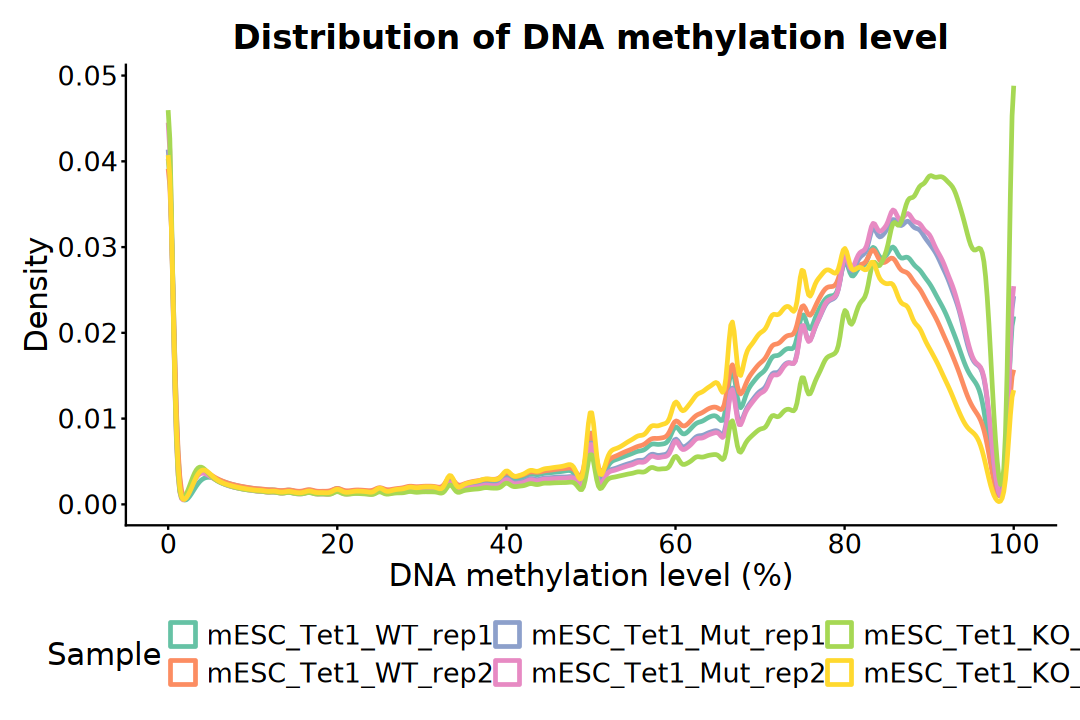

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = meth, color = sample)) +
    geom_density(linewidth = 1) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Density", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

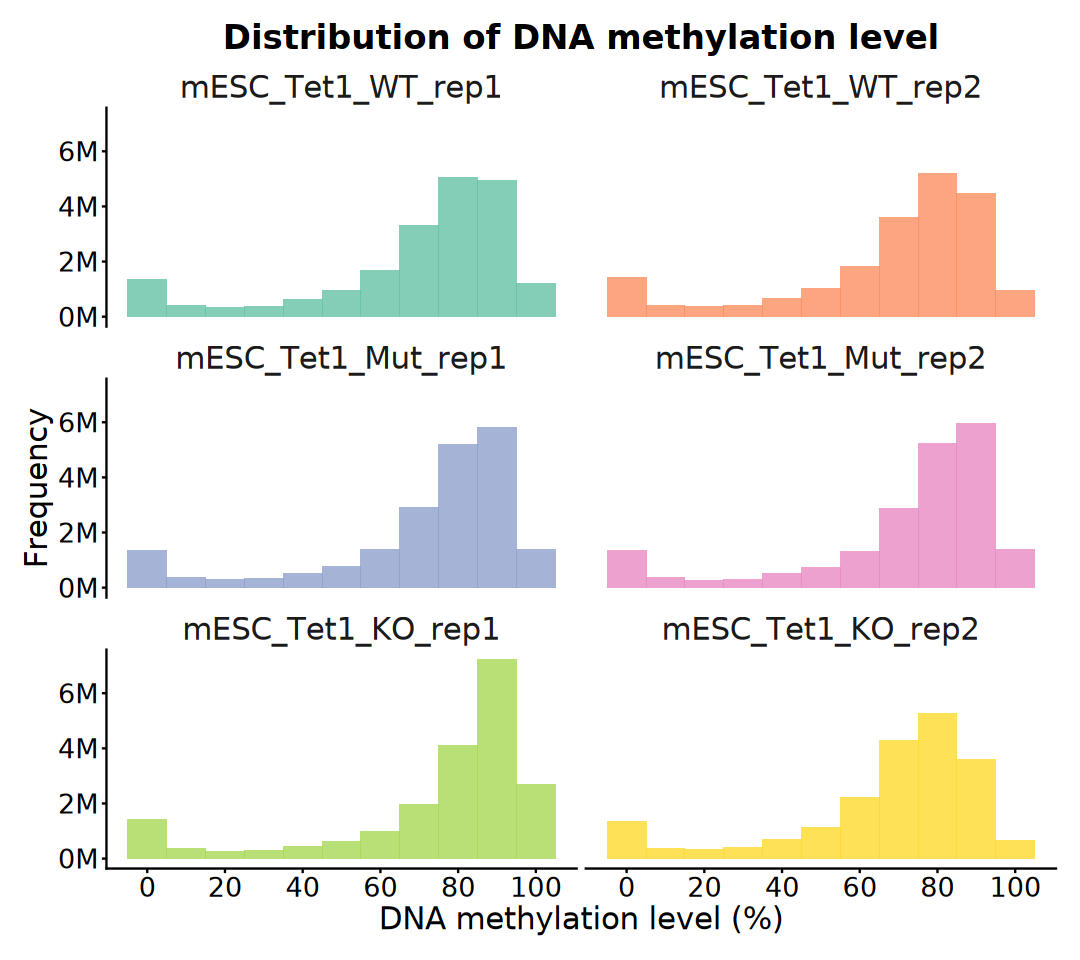

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = meth, fill = sample)) +
    geom_histogram(binwidth = 10, position = "identity", alpha = 0.8) +
    facet_wrap(~ sample, ncol = 2) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

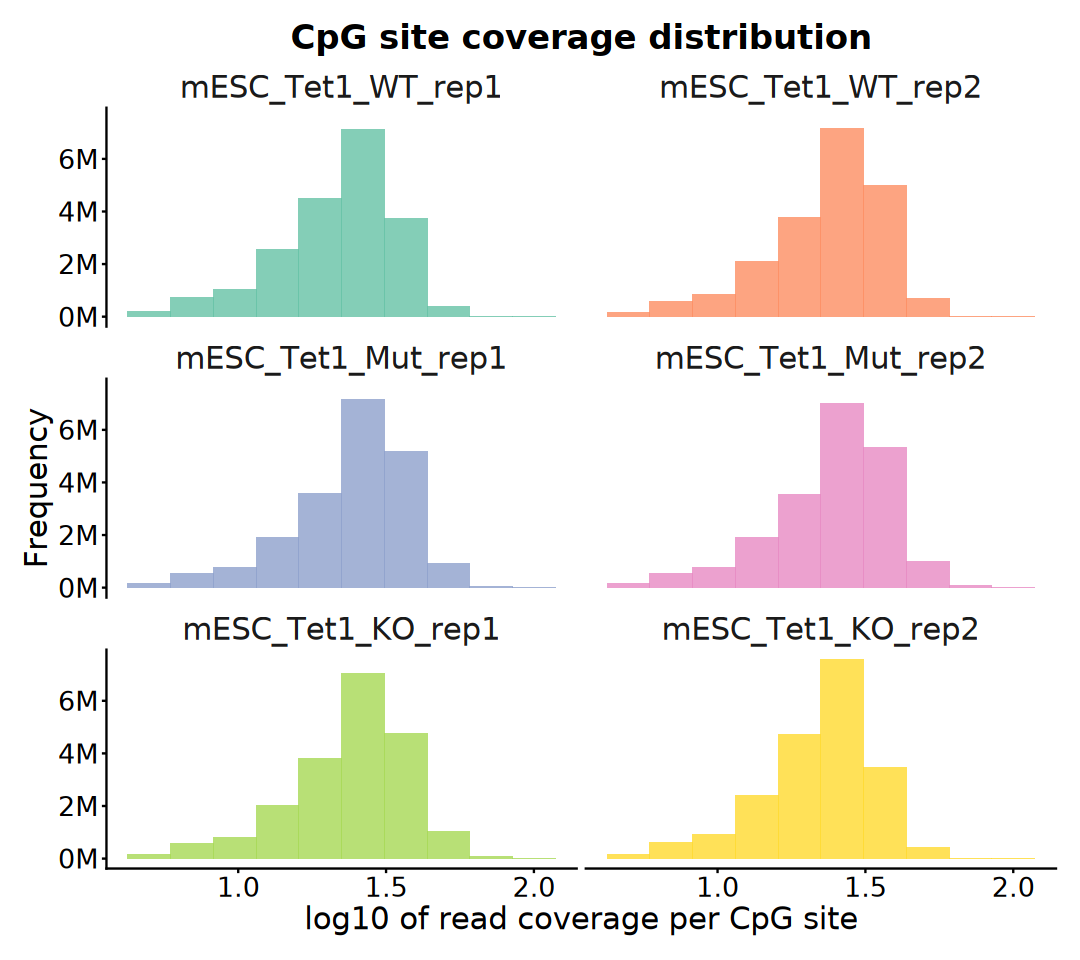

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::mutate(coverage = numCs + numTs) |>
    dplyr::select(sample, coverage) |>
    dplyr::filter(coverage <= 100) |>
    mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = log10(coverage), fill = sample)) +
    geom_histogram(bins = 10, alpha = 0.8) +
    facet_wrap( ~ sample, ncol = 2) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "CpG coverage distribution",
        x = expression(log[10] ~ "read coverage per CpG site"),
        y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Standard Plot

In [11]:
plot_df <- data.frame(
    sample = names(meth_list),
    number = sapply(meth_list, length),
    mean = sapply(meth_list, \(gr) mean(mcols(gr)$meth))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    column_to_rownames("sample")

plot_df

,number,mean,Cell,Gene,Group,Replicate
,<int>,<dbl>,<chr>,<chr>,<fct>,<fct>
mESC_Tet1_WT_rep1,20257549,69.21001,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep2,20328750,67.87418,mESC,Tet1,WT,rep2
mESC_Tet1_Mut_rep1,20304593,71.23782,mESC,Tet1,Mut,rep1
mESC_Tet1_Mut_rep2,20312711,71.59396,mESC,Tet1,Mut,rep2
mESC_Tet1_KO_rep1,20336360,74.36708,mESC,Tet1,KO,rep1
mESC_Tet1_KO_rep2,20323678,66.77281,mESC,Tet1,KO,rep2


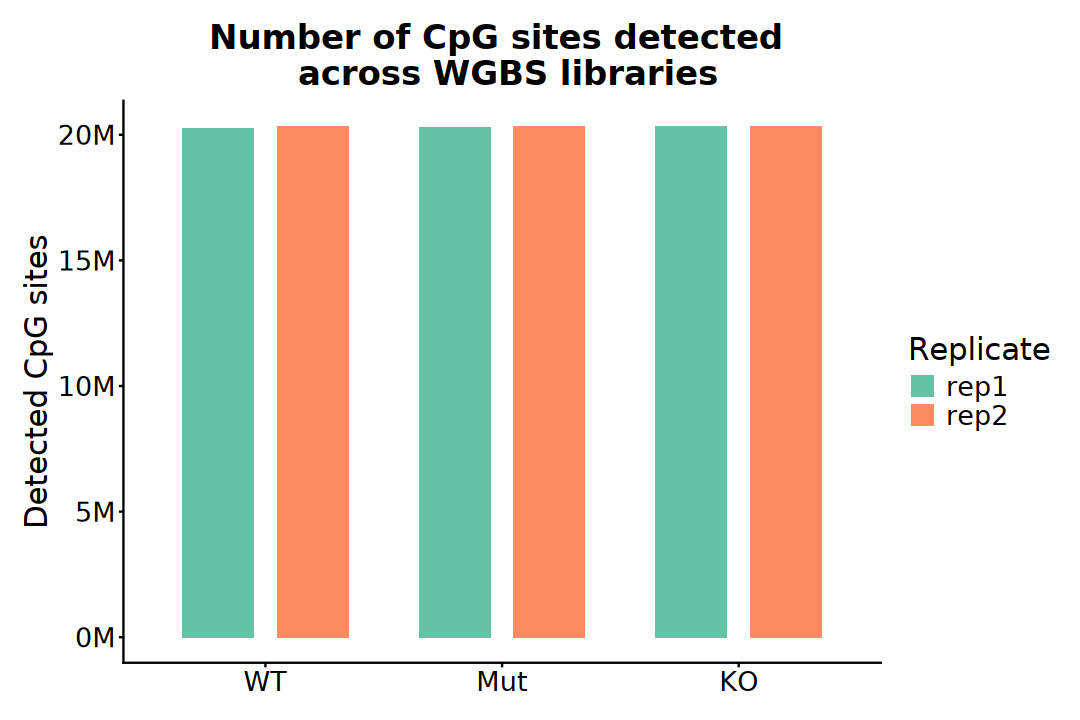

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

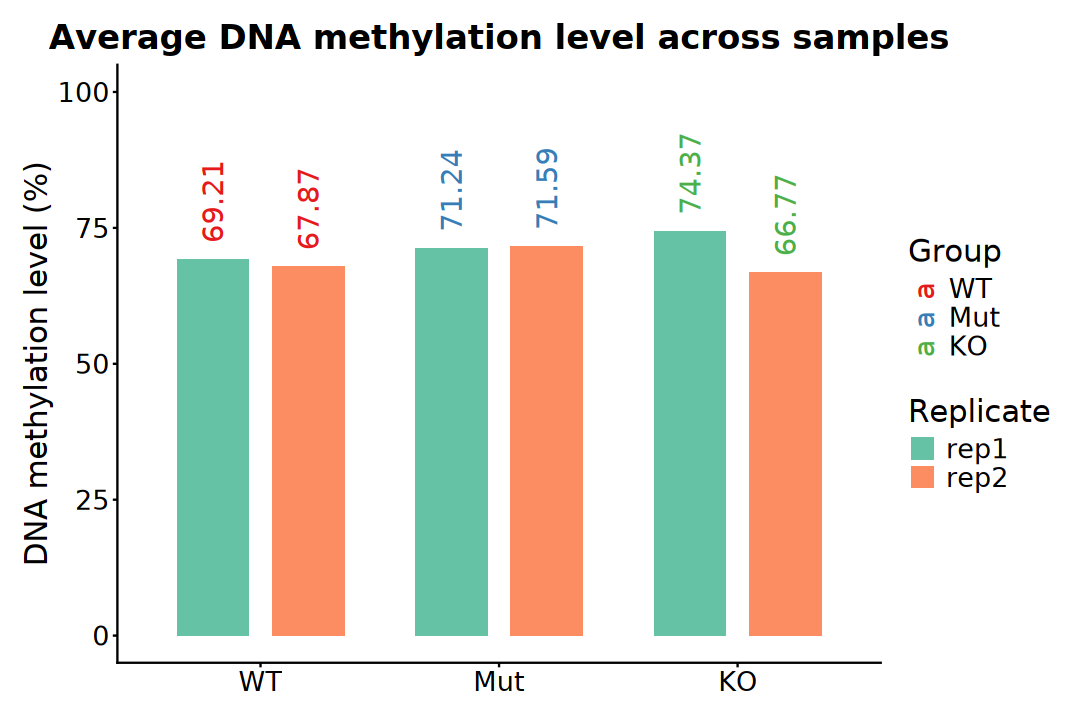

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = mean, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Group, label = sprintf("%.2f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

`stat_compare_means()` with `comparisons` displays *unadjusted* p-values (no correction for multiple comparisons).
ℹ For p-values adjusted for multiple comparisons, use `geom_pwc()`, or `stat_pvalue_manual()` together with `compare_means(..., p.adjust.method = )`.
This message is displayed once per session.


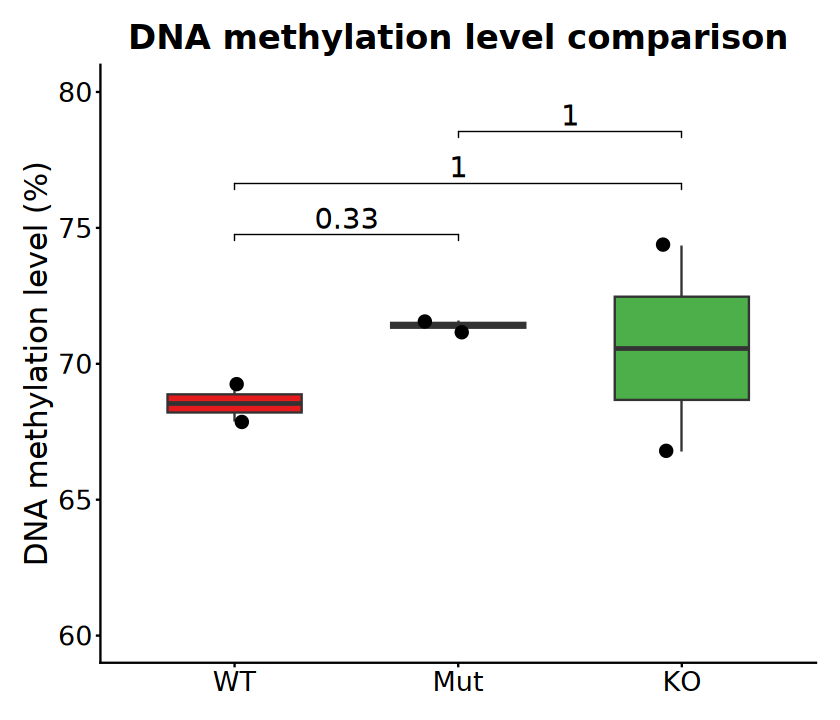

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = mean, fill = Group)) +
    geom_boxplot(width = 0.6, linewidth = 0.5, outlier.shape = NA) +
    geom_jitter(width = 0.15, size = 3, color = "black") +
    stat_compare_means(
        comparisons = combn(levels(coldata$Group), 2, simplify = FALSE), 
        method = "wilcox.test", label = "p.format", size = 6, 
        step.increase = 0.25, col = "darkblue") +
    coord_cartesian(ylim = c(60, 80)) +
    scale_fill_brewer(palette = "Set1") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "DNA methylation across groups",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [15]:
plot_df <- map_dfr(meth_list, ~ tibble(
    meth = mcols(.x)$meth), .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

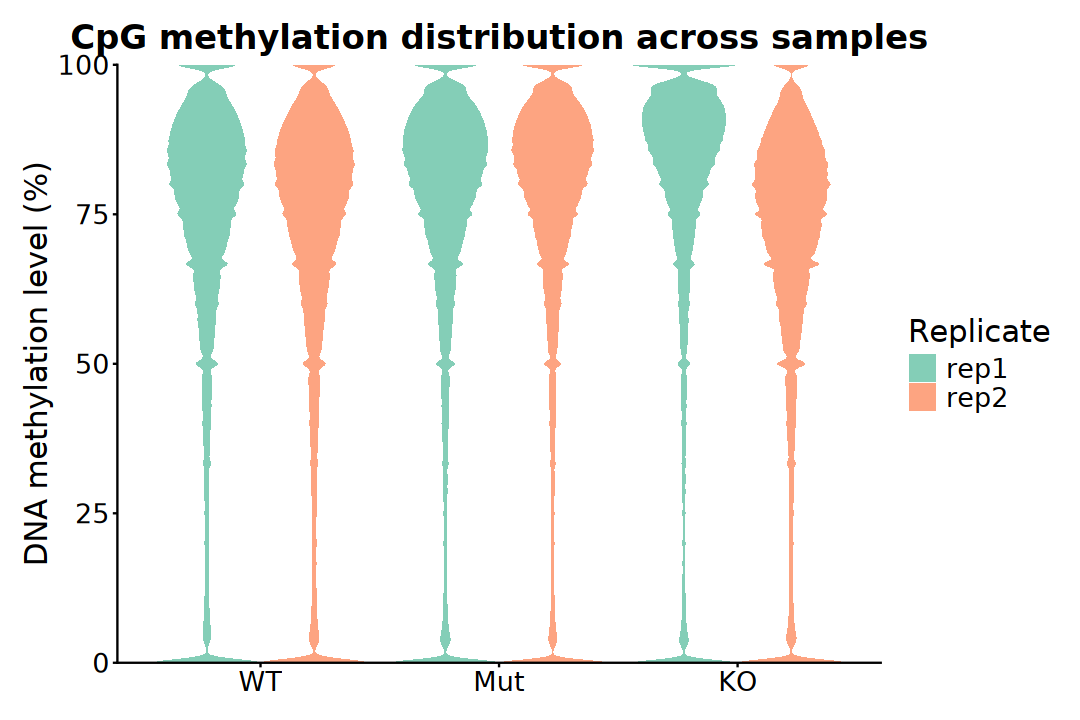

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = meth, fill = Replicate)) +
    geom_violin(trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    # geom_boxplot(
    #     width = 0.2, outlier.shape = NA, color = "grey50",
    #     position = position_dodge(width = 0.9)) +
    # stat_summary(
    #     fun = median, geom = "point", size = 2, color = "black",
    #     position = position_dodge(width = 0.9)) +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)") +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Density Scatter Plot

In [17]:
common_cpg <- Reduce(function(x, y) {
    x[findOverlaps(x, y, type = "equal") |> queryHits()]
}, meth_list) |> granges()

common_cpg

GRanges object with 19760715 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1   3000827-3000828      *
         [2]     chr1   3001007-3001008      *
         [3]     chr1   3001018-3001019      *
         [4]     chr1   3001277-3001278      *
         [5]     chr1   3001629-3001630      *
         ...      ...               ...    ...
  [19760711]     chrY 90830680-90830681      *
  [19760712]     chrY 90830692-90830693      *
  [19760713]     chrY 90830726-90830727      *
  [19760714]     chrY 90830904-90830905      *
  [19760715]     chrY 90831087-90831088      *
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

In [18]:
meth_common <- lapply(meth_list, function(gr) {
    hits <- findOverlaps(common_cpg, gr, type = "equal")
    meth <- rep(NA_real_, length(common_cpg))
    meth[queryHits(hits)] <- gr$meth[subjectHits(hits)]
    meth
})

meth_common <- as.data.frame(meth_common)
names(meth_common) <- names(meth_list)

In [ ]:
sample_pairs <- combn(names(meth_list), 2, simplify = FALSE)
sample_pairs <- Filter(function(pair) {
        r1 <- sub(".*_rep([0-9]+)$", "\\1", pair[1])
        r2 <- sub(".*_rep([0-9]+)$", "\\1", pair[2])
        r1 == r2}, sample_pairs)

sample_pairs

[[1]]
[1] "mESC_Tet1_WT_rep1"  "mESC_Tet1_Mut_rep1"

[[2]]
[1] "mESC_Tet1_WT_rep1" "mESC_Tet1_KO_rep1"

[[3]]
[1] "mESC_Tet1_WT_rep2"  "mESC_Tet1_Mut_rep2"

[[4]]
[1] "mESC_Tet1_WT_rep2" "mESC_Tet1_KO_rep2"

[[5]]
[1] "mESC_Tet1_Mut_rep1" "mESC_Tet1_KO_rep1" 

[[6]]
[1] "mESC_Tet1_Mut_rep2" "mESC_Tet1_KO_rep2"

In [20]:
plot_methylation_comparison <- function(plot_df, sample_x, sample_y) {
    # Linear regression
    fit <- lm(methy_y ~ methy_x, data = plot_df)

    # Spearman correlation
    cor_res <- cor.test(
        plot_df$methy_x, plot_df$methy_y, method = "spearman", exact = FALSE)

    # scatter plot
    smoothScatter(
        plot_df$methy_x, plot_df$methy_y,
        colramp = colorRampPalette(brewer.pal(9, "Blues")),
        xlab = sample_x, ylab = sample_y, cex = 0)
    abline(a = 0, b = 1, col = "darkblue", lty = 2, lwd = 3)
    abline(fit, col = "darkred", lty = 2, lwd = 3)
    legend(
        "topleft", lty = 2, lwd = 2, col = 'black', border = NA, 
        text.col = "black", box.col = NA, bg = NA,
        legend = c(
            paste0("Linear slope: ", round(coef(fit)[2], 2)),
            paste0("Spearman \u03c1: ", round(cor_res$estimate, 2)),
            paste0("P-value: ", format.pval(
                cor_res$p.value, digits = 2, eps = 1e-100))))
}

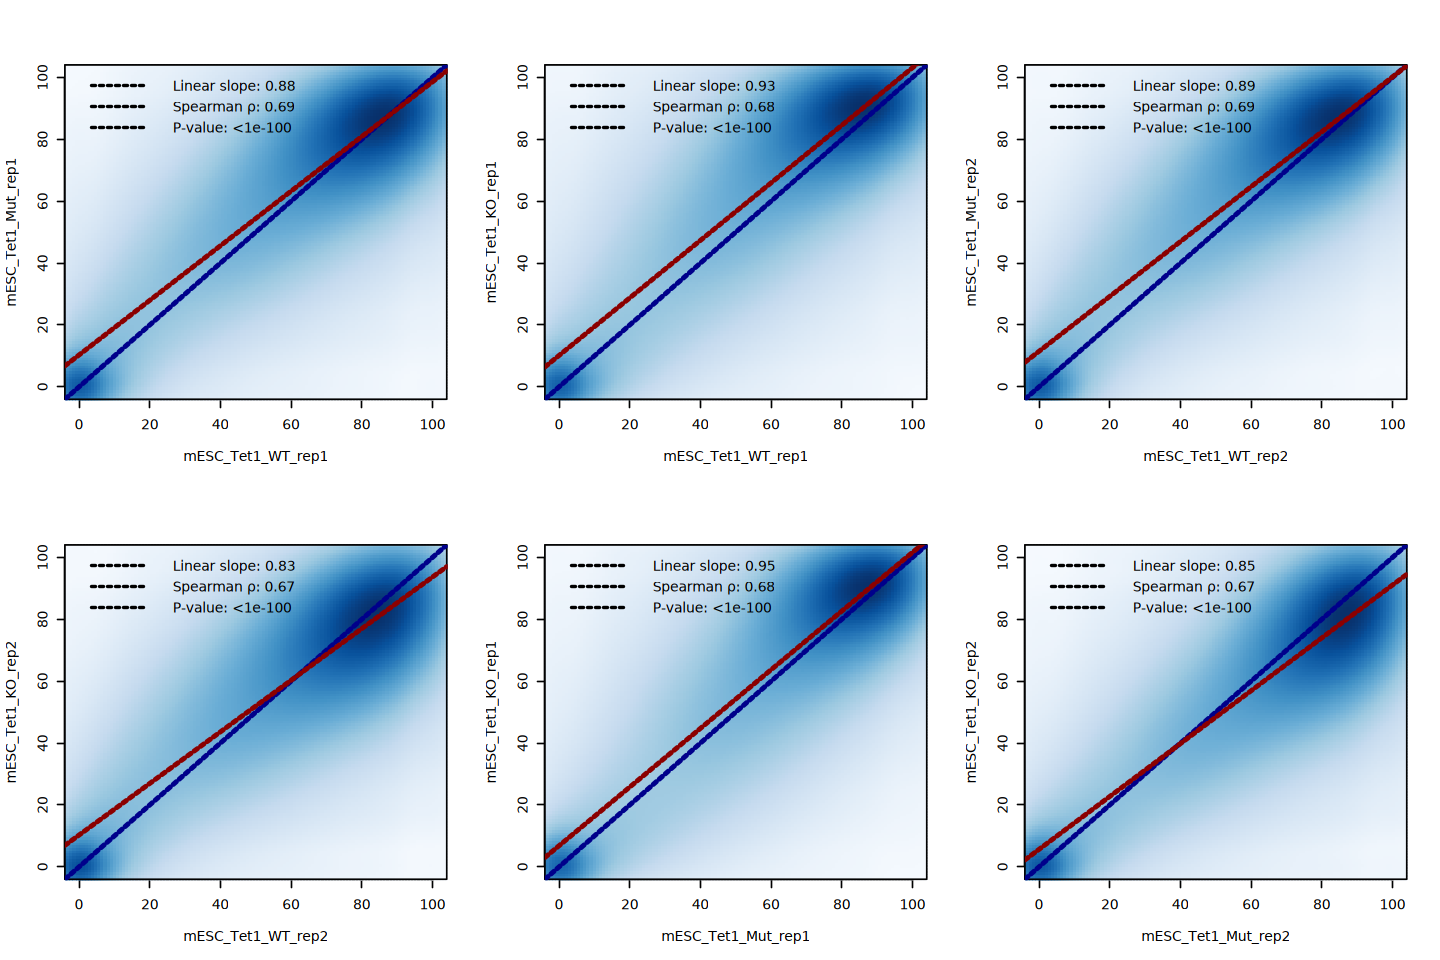

In [21]:
options(repr.plot.width = 12, repr.plot.height = 8)

par(mfrow = c(2, 3))

for (pair in sample_pairs) {
    plot_df <- data.frame(
        methy_x = meth_common[[pair[1]]],
        methy_y = meth_common[[pair[2]]])
    plot_methylation_comparison(plot_df, pair[1], pair[2])
}

## 3). Genomic Signal Plot

In [22]:
chr_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chr_idx]
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
names(bins) <- floor((start(bins) + end(bins)) / 2)

In [23]:
bin_stats_list <- lapply(names(meth_list), function(idx) {
    gr <- meth_list[[idx]]
    gr <- gr[seqnames(gr) == chr_idx]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        numCs = gr$numCs[queryHits(hits)],
        numTs = gr$numTs[queryHits(hits)])

    bin_stats <- df[, list(
        numCs = sum(numCs), numTs = sum(numTs)), by = bin_idx]
    bin_stats[, meth := numCs / (numCs + numTs) * 100]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$numCs <- bin_stats$numCs
    result$numTs <- bin_stats$numTs
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

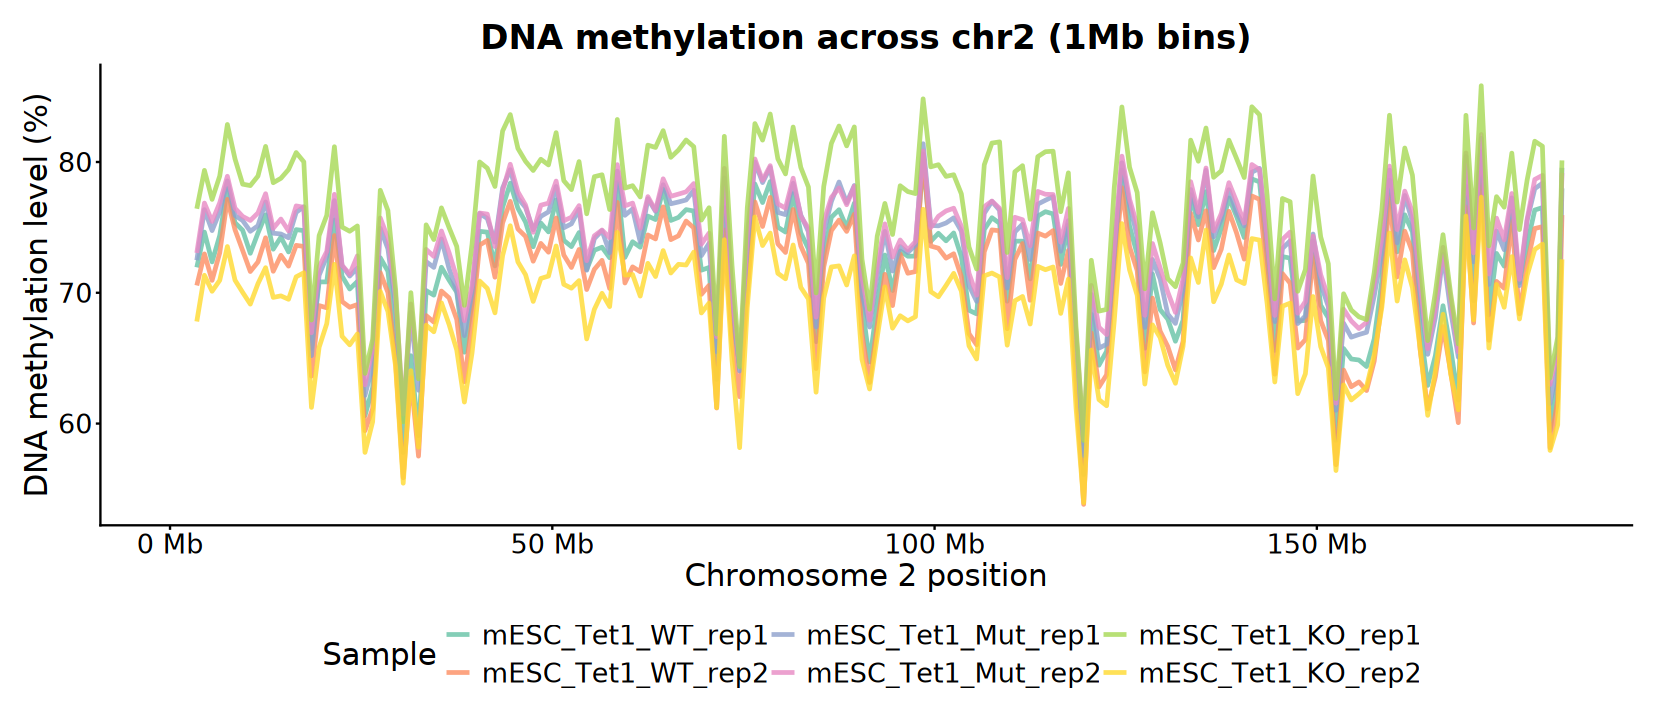

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

do.call(c, bin_stats_list) |> as.data.frame() |>
    mutate(position = (start + end) / 2) |>
    mutate(sample = factor(sample, levels = names(meth_list))) |>
ggplot(aes(x = position, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    scale_x_continuous(
        limits = c(1, chrom_sizes), breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = paste0("DNA methylation across ", chr_idx, " (1-Mb bins)"),
        x = paste0(chr_idx, " position"), 
        y = "DNA methylation level (%)",
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 2, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Metagene Profile

In [25]:
GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

  66 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [26]:
CGI <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/cpgIslandExt.txt",
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length",
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [27]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  10988   13540 


    Promoter non_Promoter 
        9449         3459 

### a). Genes

In [28]:
gene_mat_List <- lapply(
    meth_list, normalizeToMatrix, GENES, value_column = "meth",
    extend = 2000, mean_mode = "absolute", w = 50, target_ratio = 0.4,
    background = NA, smooth = FALSE)

In [29]:
partition <- PROMOTERS$CGI_status

col_cluster <- c(CGI  = "#756BB1", non_CGI = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "CpG status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [30]:
ht_list <- Heatmap(
    partition, name = "Genes", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(gene_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        gene_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

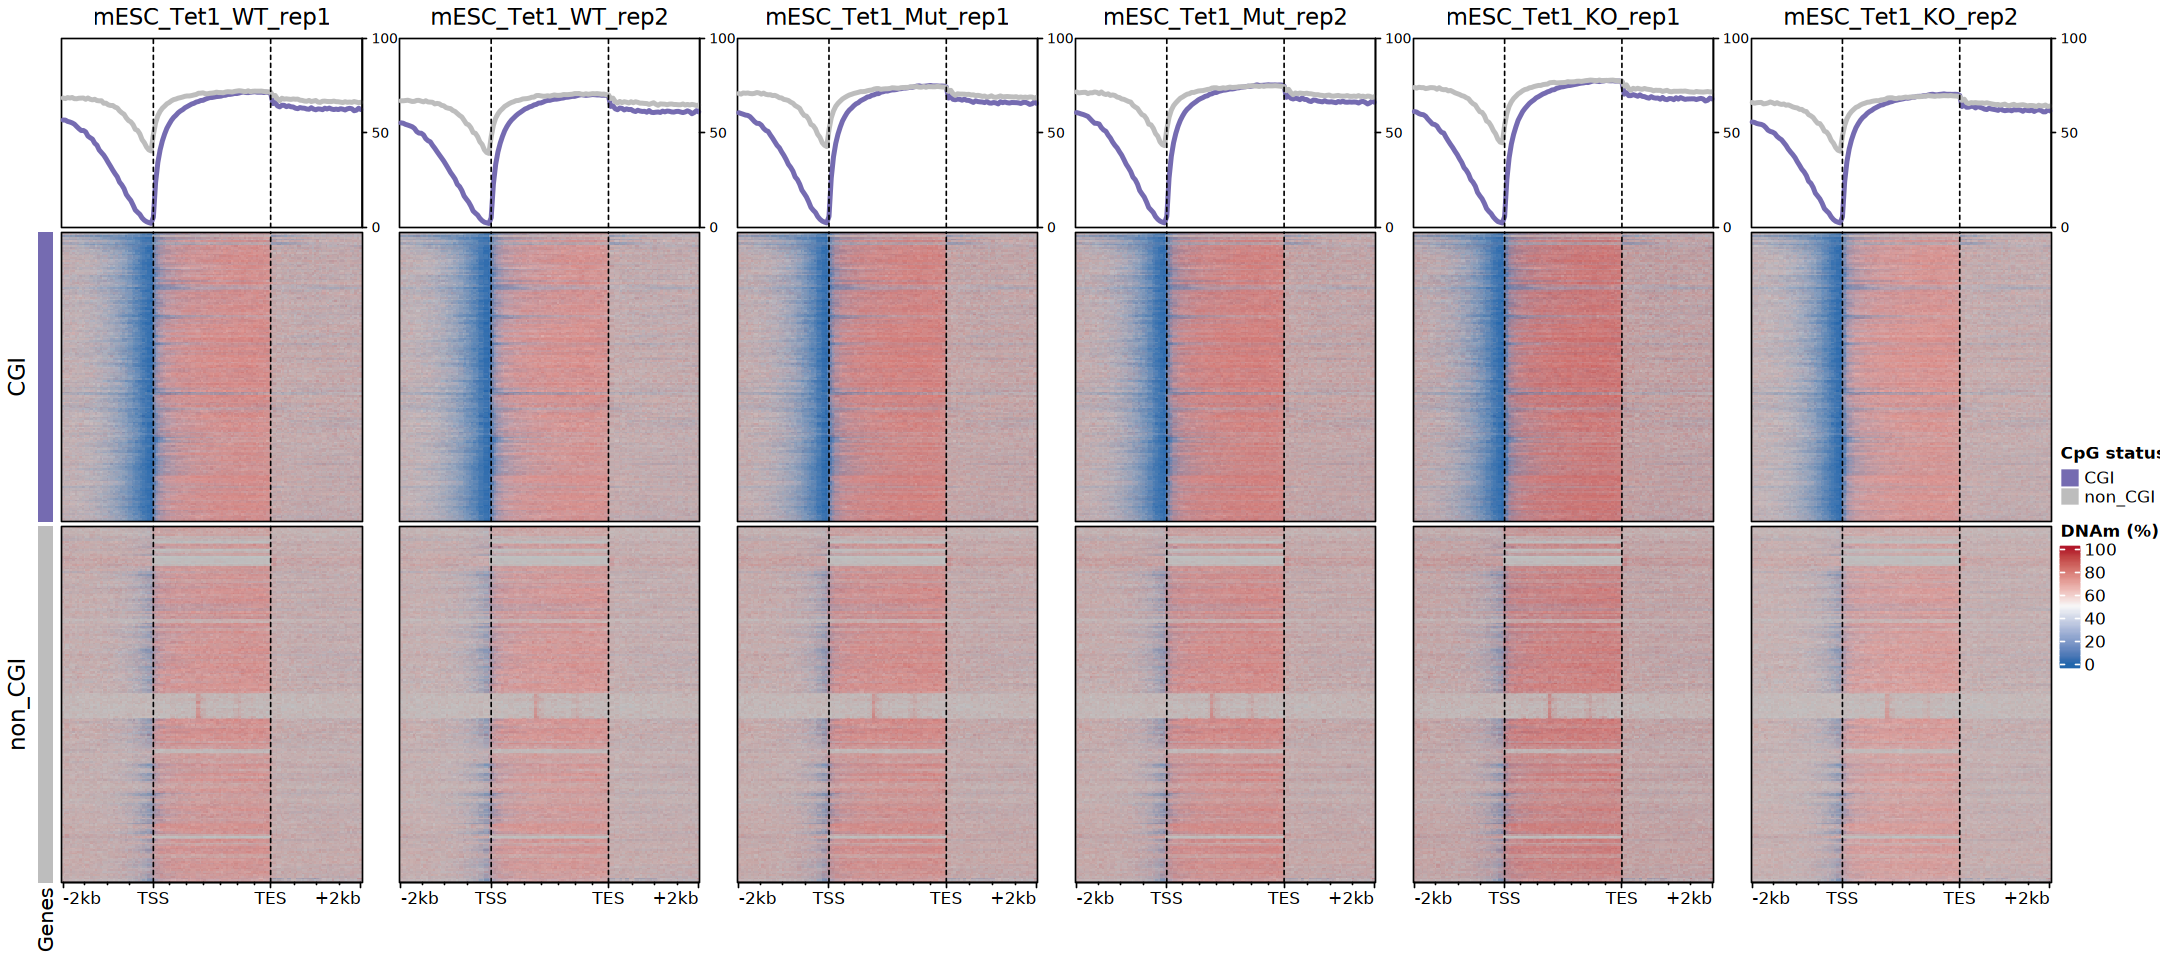

In [31]:
options(repr.plot.width = 18, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(gene_mat_List))), "mm"))

In [32]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

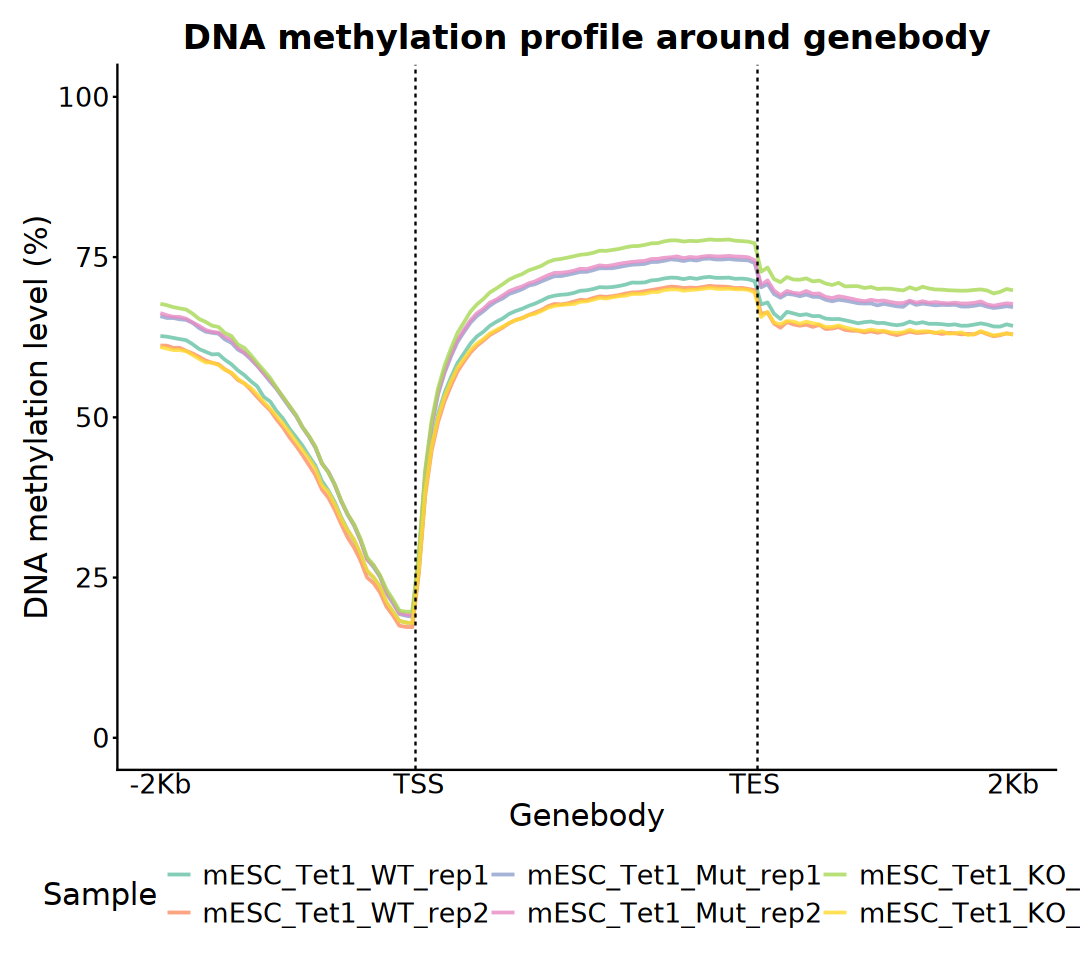

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [34]:
cgi_mat_List <- lapply(
    meth_list, normalizeToMatrix, CGI, value_column = "meth",
    extend = 4000, mean_mode = "absolute", w = 50, target_ratio = 0.3,
    background = NA, smooth = FALSE)

In [35]:
partition <- CGI$Promoter_status

col_cluster <- c(Promoter  = "#1B9E77", non_Promoter = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "Promoter status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [36]:
ht_list <- Heatmap(
    partition, name = "CGI", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(cgi_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        cgi_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-4kb", "start", "end", "+4kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

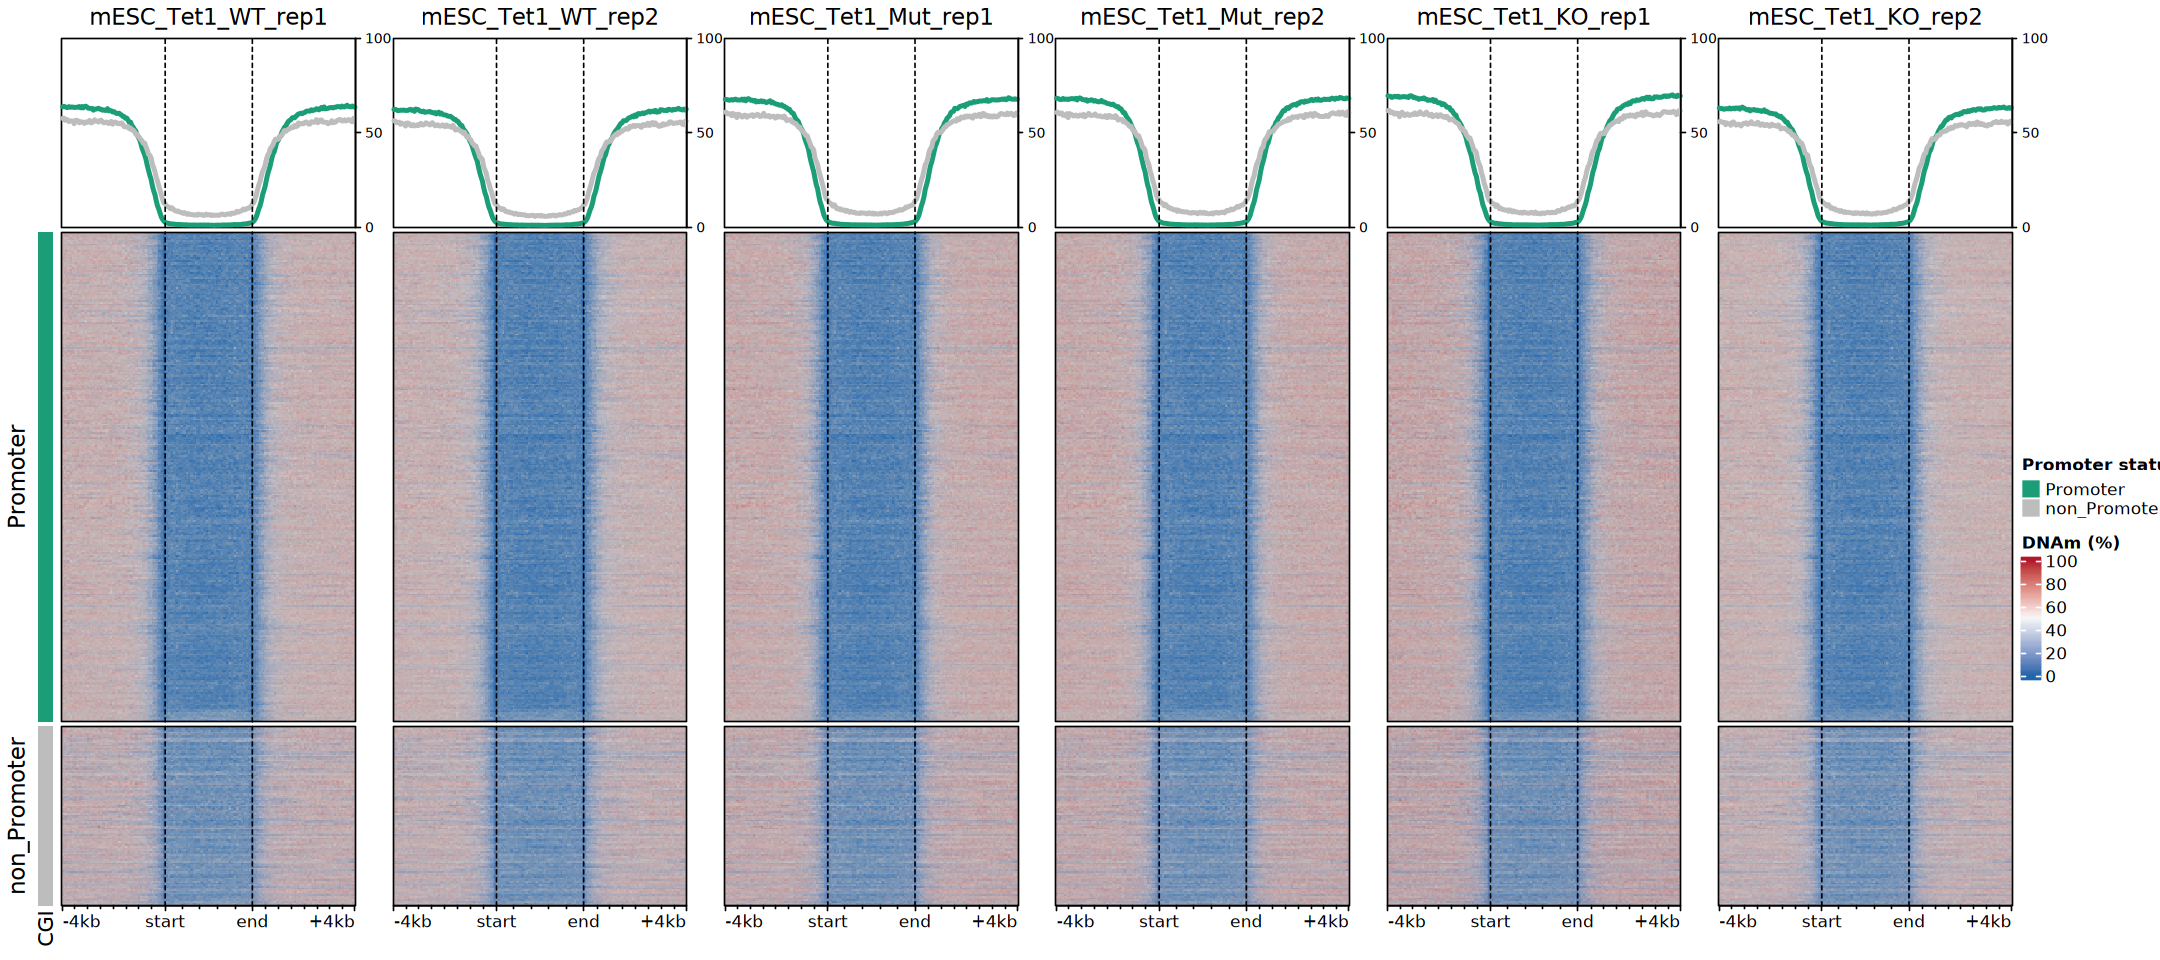

In [37]:
options(repr.plot.width = 18, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(cgi_mat_List))), "mm"))

In [38]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

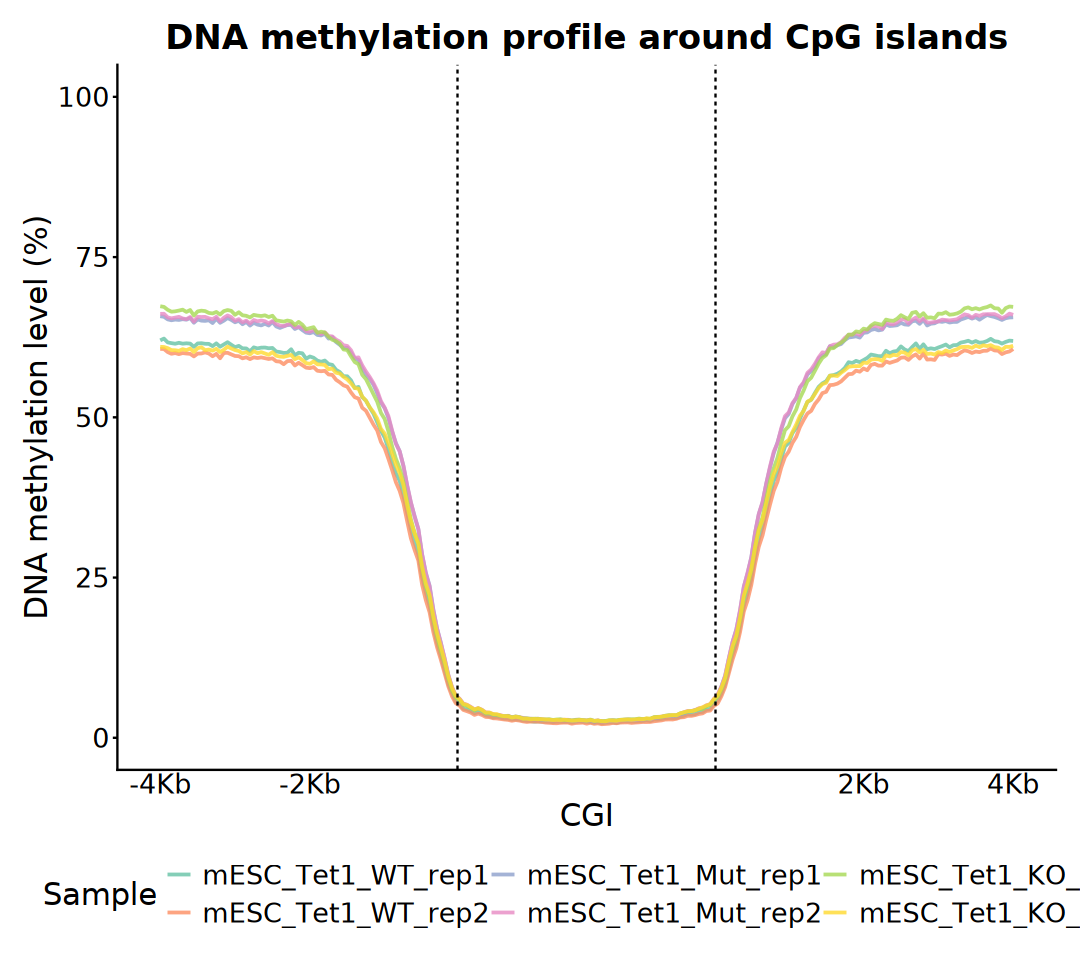

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    scale_x_discrete(
        "CGI", expand = c(0.05, 0.05), 
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

## 5). DNAm Distribution

In [40]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  66 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [41]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [42]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [43]:
get_profile_data <- function(
    gr, region, region_id, bin = 50, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)

    if(length(hits) == 0) return(NULL)

    gr_sub <- gr[queryHits(hits)]
    region_sub <- region[subjectHits(hits)]

    rel_pos <- (start(gr_sub) - start(region_sub)) / width(region_sub)
    is_minus <- as.character(strand(region_sub)) == "-"
    rel_pos[is_minus] <- 1 - rel_pos[is_minus]

    bin_idx <- ceiling(rel_pos * bin)
    bin_idx[bin_idx == 0] <- 1
    bin_idx[bin_idx > bin] <- bin

    if (method == "mean") {
        vals <- mcols(gr_sub)[[meth_col]]
        mean <- mean(vals, na.rm = TRUE)
        df <- tibble(bin = bin_idx, meth = vals) |> 
            group_by(bin) |>
            summarise(mean = mean(meth, na.rm = TRUE), .groups = "drop") |>
            mutate(region = region_id)
    } else if (method == "ratio") {
        numCs <- mcols(gr_sub)[[numCs_col]]
        numTs <- mcols(gr_sub)[[numTs_col]]
        df <- tibble(bin = bin_idx, numCs = numCs, numTs = numTs) |>
            group_by(bin) |>
            summarise(
                mean = sum(numCs) / sum(numCs + numTs) * 100, 
                .groups = "drop") |>
            mutate(region = region_id)
    }

    return(df)
}

In [44]:
region_index <- c(
    "Promoter", "FiveUTR", "Exon", "Intron", "ThreeUTR", 
    "Downstream", "Intergenic")

profiles_list <- list()

for (sample_idx in names(meth_list)) {
    meth <- meth_list[[sample_idx]]
    result <- lapply(region_index, function(idx) {
        region <- region_list[[idx]]
        df <- get_profile_data(
            meth, region, idx, bin = 50, method = "ratio")
        return(df)
    })

    profiles_list[[sample_idx]] <- bind_rows(result) |>
        mutate(
            sample = sample_idx, 
            region = factor(region, levels = region_index))
}

In [45]:
plot_df <- bind_rows(profiles_list) |>
    mutate(region_idx = as.numeric(region) - 1) |>
    mutate(global_idx = (region_idx * 50) + bin) |>
    mutate(sample = factor(sample, levels = names(meth_list)))

head(plot_df)

bin,mean,region,sample,region_idx,global_idx
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,60.59356,Promoter,mESC_Tet1_WT_rep1,0,1
2,60.37892,Promoter,mESC_Tet1_WT_rep1,0,2
3,60.70383,Promoter,mESC_Tet1_WT_rep1,0,3
4,60.07212,Promoter,mESC_Tet1_WT_rep1,0,4
5,60.11762,Promoter,mESC_Tet1_WT_rep1,0,5
6,59.28624,Promoter,mESC_Tet1_WT_rep1,0,6


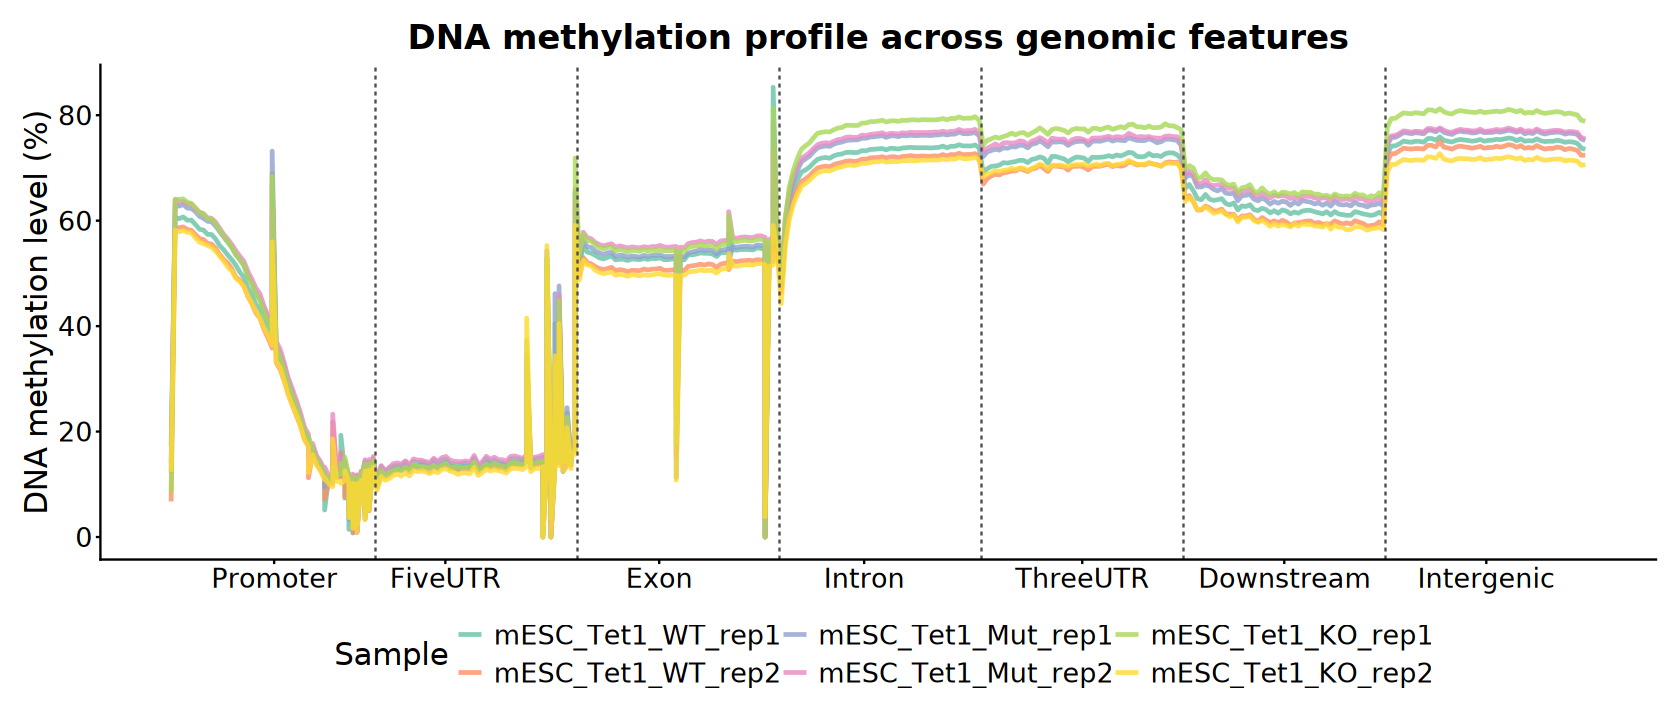

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

x_labels_pos <- plot_df |> group_by(region) |>
    summarise(center_idx = mean(global_idx), .groups = "drop")
vlines_pos <- seq(50 + 0.5, max(plot_df$global_idx) - 50 + 0.5, by = 50)

ggplot(plot_df, aes(x = global_idx, y = mean, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = vlines_pos, color = "grey30", linetype = "dashed") +
    scale_x_continuous(
        breaks = x_labels_pos$center_idx, 
        labels = x_labels_pos$region) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profiles across genomic regions",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [47]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [48]:
meth_df <- imap_dfr(meth_list, function(gr, sample_id) {
    get_region_data(gr = gr, region_list = region_list, method = "ratio")
}, .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(region = factor(region, levels = names(region_list)))

head(meth_df)

sample,region,numCpG,mean,Cell,Gene,Group,Replicate
<chr>,<fct>,<int>,<dbl>,<chr>,<chr>,<fct>,<fct>
mESC_Tet1_WT_rep1,CGI,964393,3.268743,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep1,CGI_Shore,770634,36.139456,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep1,CGI_Shelf,486999,66.008169,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep1,Promoter,1464978,26.409290,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep1,Exon,3147116,53.490836,mESC,Tet1,WT,rep1
mESC_Tet1_WT_rep1,Intron,32897684,71.483895,mESC,Tet1,WT,rep1


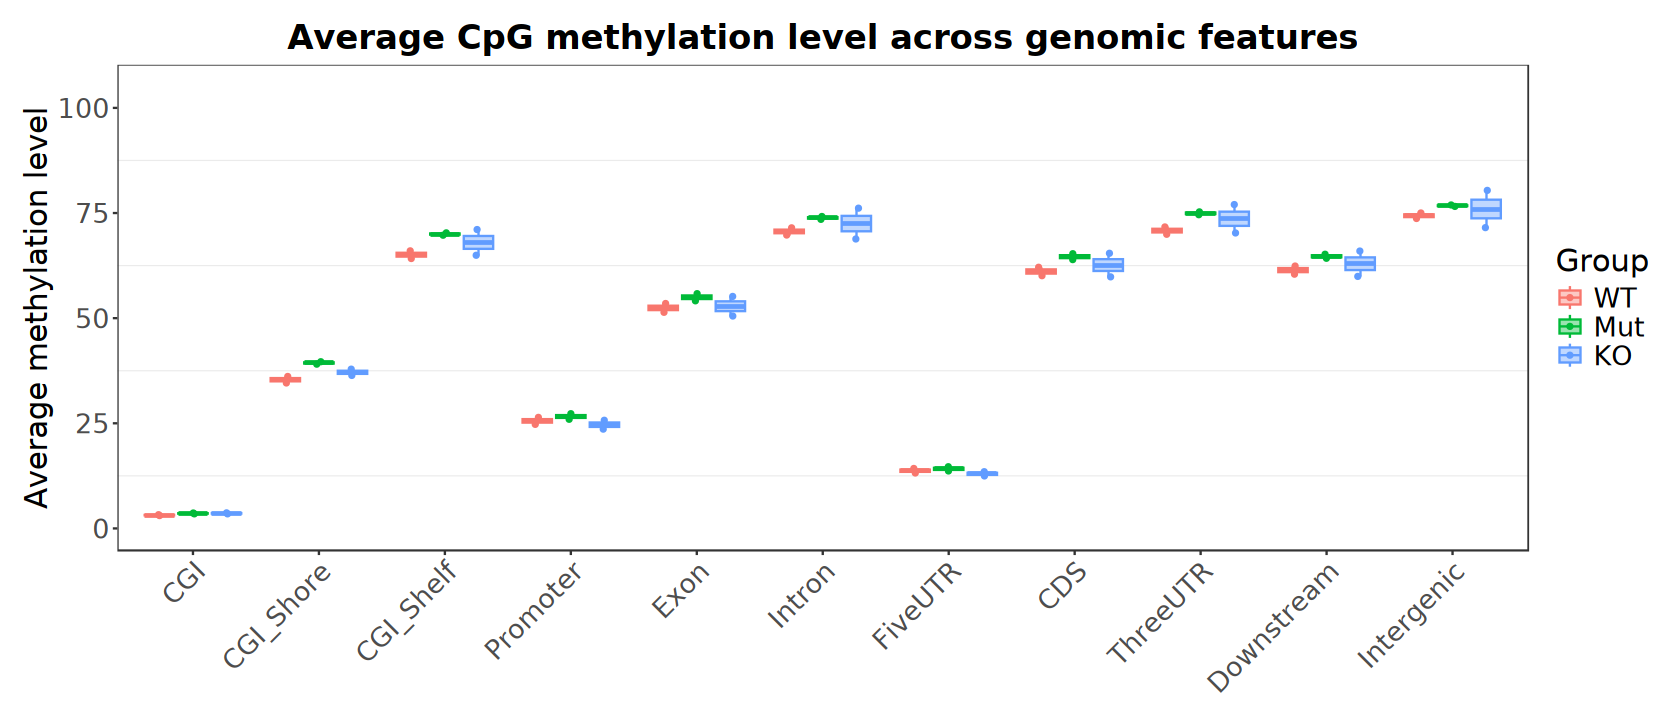

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_boxplot(
        aes(color = Group, fill = Group), 
        position = position_dodge(width = 0.8),
        width = 0.7, outlier.shape = NA, alpha = 0.4) +
    geom_point(
        aes(color = Group), size = 1, alpha = 1, 
        position = position_jitterdodge(
            jitter.width = 0.1, dodge.width = 0.8)) +
    coord_cartesian(ylim = c(0, 105)) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Group", fill = "Group") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

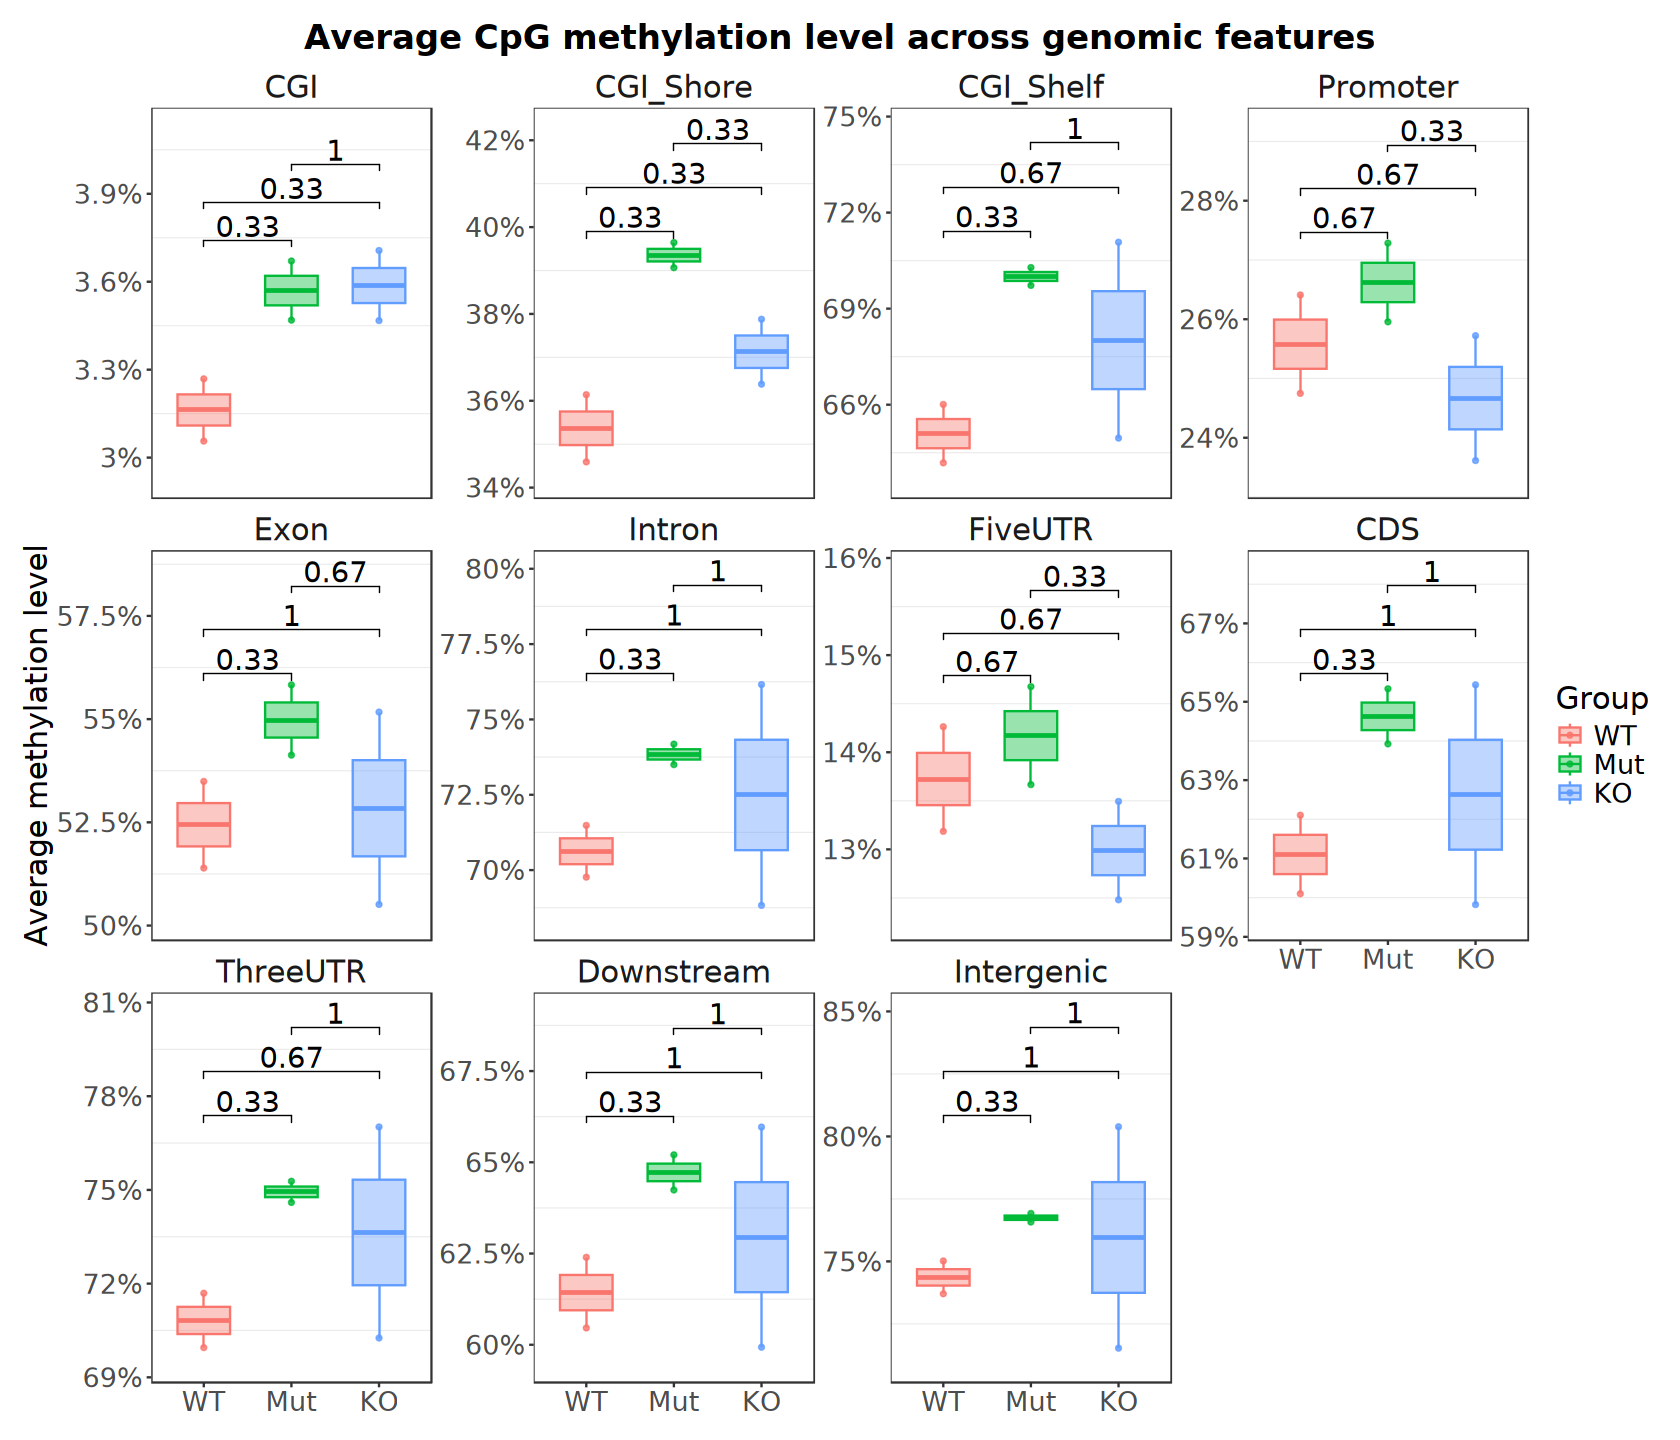

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(meth_df, aes(x = Group, y = mean)) +
    geom_boxplot(
        aes(color = Group, fill = Group), 
        width = 0.6, outlier.shape = NA, alpha = 0.4) +
    geom_point(
        aes(color = Group), size = 1, alpha = 0.8) +
    stat_compare_means(
        comparisons = combn(levels(meth_df$Group), 2, simplify = FALSE), 
        method = "wilcox.test", label = "p.format", size = 6, 
        step.increase = 0.2, col = "darkblue") +
    facet_wrap(~ region, nrow = 3, scales = "free_y") +
    scale_y_continuous(
        expand = c(0.1, 0.1), 
        labels = function(x) paste0(x, "%")) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Group", fill = "Group") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

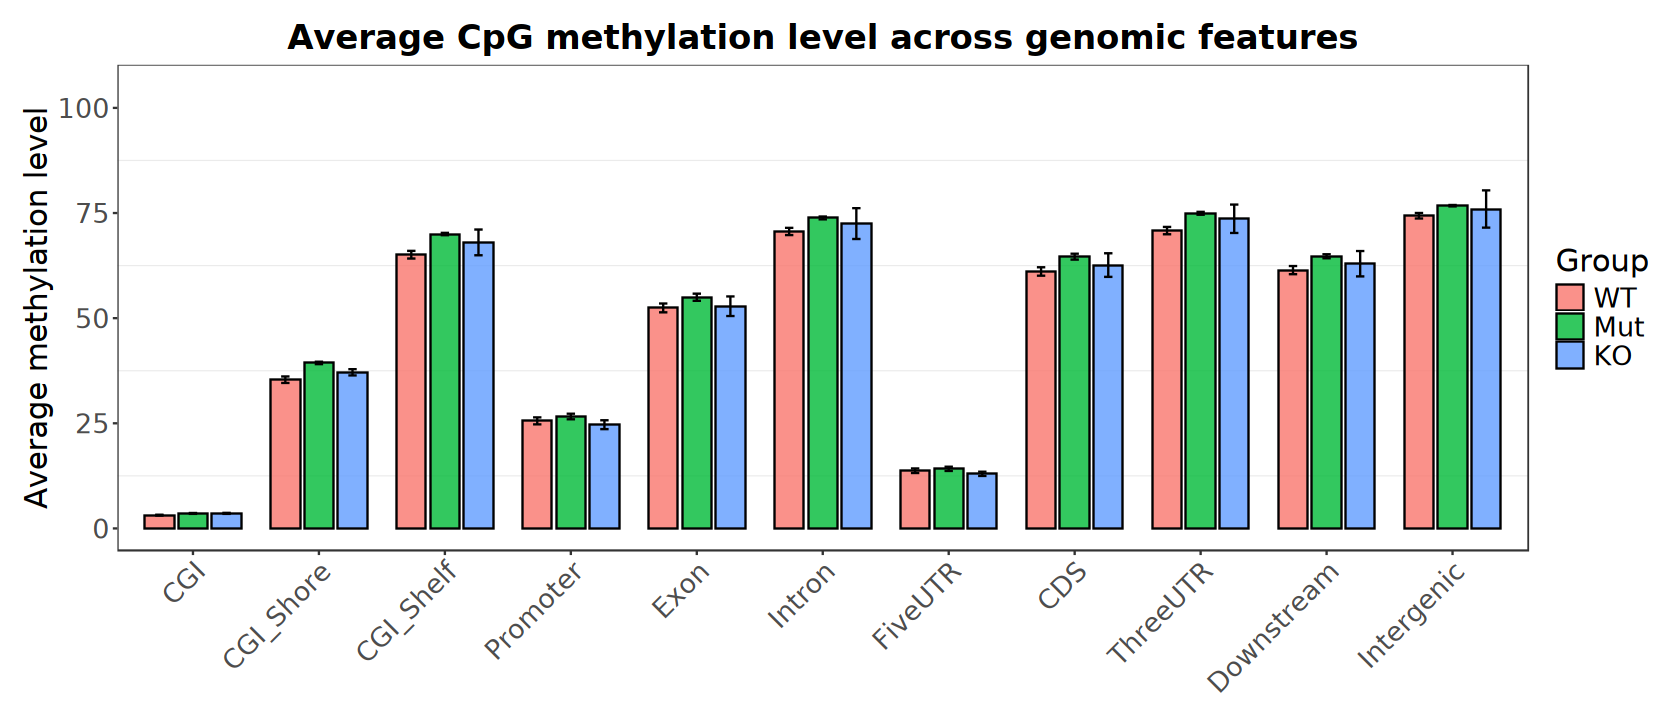

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean, color = Group, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", 
        position = position_dodge(width = 0.8), 
        color = "black", alpha = 0.8, width = 0.7) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black",
        position = position_dodge(width = 0.8), width = 0.2) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)") +
    coord_cartesian(ylim = c(0, 105)) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# 5. DMRs

## 1). [bsseq](https://www.bioconductor.org/packages/release/bioc/html/bsseq.html)

In [73]:
suppressPackageStartupMessages(library(bsseq))
suppressPackageStartupMessages(library(BiocParallel))

In [74]:
CpG <- bsseq::findLoci("CG", genome) |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")

In [77]:
# ~ 1 min
bs_obj <- read.bismark(
    files = cov_files, loci = CpG, colData = coldata, 
    rmZeroCov = FALSE, strandCollapse = TRUE)

bs_obj

An object of type 'BSseq' with
  21867550 methylation loci
  6 samples
has not been smoothed
All assays are in-memory

In [ ]:
# Extreme memory consumption
# ~ 40 min, Threads: 4, memory: 64G
bs_obj_fit <- BSmooth(BSseq = bs_obj, BPPARAM = MulticoreParam(workers = 4))

bs_obj_fit

R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_

An object of type 'BSseq' with
  21867550 methylation loci
  6 samples
has been smoothed with
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
All assays are in-memory

In [79]:
saveRDS(bs_obj_fit, file.path(data_dir, "output_BSseq_BSmooth_Object.rds"))

In [82]:
bs_obj_fit_cov <- getCoverage(bs_obj_fit)

keep_idx <- which(
    rowSums(bs_obj_fit_cov[
        , bs_obj_fit$Group == "WT", drop = FALSE] >= 5) >= 2 & 
    rowSums(bs_obj_fit_cov[
        , bs_obj_fit$Group == "Mut", drop = FALSE] >= 5) >= 2 & 
    rowSums(bs_obj_fit_cov[
        , bs_obj_fit$Group == "KO", drop = FALSE] >= 5) >= 2
)

cat("Number of loci kept after filtering:", length(keep_idx), "\n")

Number of loci kept after filtering: 19760715 


In [83]:
bs_obj_filter <- bs_obj_fit[keep_idx, ]

bs_obj_filter

An object of type 'BSseq' with
  19760715 methylation loci
  6 samples
has been smoothed with
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
All assays are in-memory

In [84]:
pData(bs_obj_filter)

DataFrame with 6 rows and 4 columns
                          Cell        Gene    Group Replicate
                   <character> <character> <factor>  <factor>
mESC_Tet1_WT_rep1         mESC        Tet1      WT       rep1
mESC_Tet1_WT_rep2         mESC        Tet1      WT       rep2
mESC_Tet1_Mut_rep1        mESC        Tet1      Mut      rep1
mESC_Tet1_Mut_rep2        mESC        Tet1      Mut      rep2
mESC_Tet1_KO_rep1         mESC        Tet1      KO       rep1
mESC_Tet1_KO_rep2         mESC        Tet1      KO       rep2

In [ ]:
# ~ 1 min
bs_obj_tstat_ko_wt <- BSmooth.tstat(
    bs_obj_filter, group1 = 5:6, group2 = 1:2, 
    estimate.var = "group2", local.correct = TRUE)

bs_obj_tstat_ko_wt

[BSmooth.tstat] preprocessing ... 

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 19760715 out-of-bound ranges located on sequences
  chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12,
  chr13, chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that
  ranges located on a sequence whose length is unknown (NA) or on a circular
  sequence are not considered out-of-bound (use seqlengths() and isCircular()
  to get the lengths and circularity flags of the underlying sequences). You
  can use trim() to trim these ranges. See ?`trim,GenomicRanges-method` for
  more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 21 out-of-bound ranges located on sequences chr1,
  chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13,
  chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that ranges
  located on a sequence whose length is unknown (NA) or on a circula

done in 20.3 sec
[BSmooth.tstat] computing stats within groups ... done in 3.7 sec
[BSmooth.tstat] computing stats across groups ... done in 41.5 sec


An object of type 'BSseqTstat' with
  19760715 methylation loci
based on smoothed data:
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
with parameters
  BSmooth.tstat (local.correct = TRUE, maxGap = 100000000) 

In [86]:
# ~ 1 min
bs_obj_tstat_mut_wt <- BSmooth.tstat(
    bs_obj_filter, group1 = 3:4, group2 = 1:2, 
    estimate.var = "group2", local.correct = TRUE, verbose = FALSE)

bs_obj_tstat_mut_wt

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 19760715 out-of-bound ranges located on sequences
  chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12,
  chr13, chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that
  ranges located on a sequence whose length is unknown (NA) or on a circular
  sequence are not considered out-of-bound (use seqlengths() and isCircular()
  to get the lengths and circularity flags of the underlying sequences). You
  can use trim() to trim these ranges. See ?`trim,GenomicRanges-method` for
  more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 21 out-of-bound ranges located on sequences chr1,
  chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13,
  chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that ranges
  located on a sequence whose length is unknown (NA) or on a circula

An object of type 'BSseqTstat' with
  19760715 methylation loci
based on smoothed data:
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
with parameters
  BSmooth.tstat (local.correct = TRUE, maxGap = 100000000) 

In [87]:
# ~ 1 min
bs_obj_tstat_ko_mut <- BSmooth.tstat(
    bs_obj_filter, group1 = 5:6, group2 = 3:4, 
    estimate.var = "group2", local.correct = TRUE, verbose = FALSE)

bs_obj_tstat_ko_mut

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 19760715 out-of-bound ranges located on sequences
  chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12,
  chr13, chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that
  ranges located on a sequence whose length is unknown (NA) or on a circular
  sequence are not considered out-of-bound (use seqlengths() and isCircular()
  to get the lengths and circularity flags of the underlying sequences). You
  can use trim() to trim these ranges. See ?`trim,GenomicRanges-method` for
  more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 21 out-of-bound ranges located on sequences chr1,
  chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13,
  chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that ranges
  located on a sequence whose length is unknown (NA) or on a circula

An object of type 'BSseqTstat' with
  19760715 methylation loci
based on smoothed data:
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
with parameters
  BSmooth.tstat (local.correct = TRUE, maxGap = 100000000) 

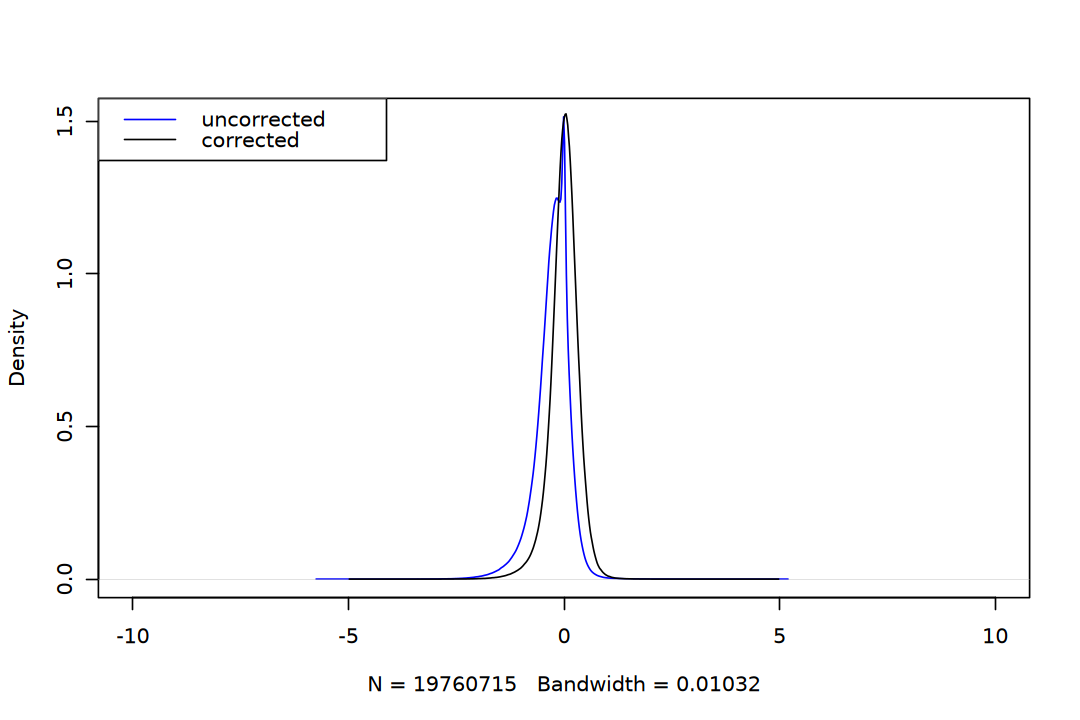

In [88]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(bs_obj_tstat_ko_wt)

In [ ]:
# bsseq_dmrs <- dmrFinder(bs_obj_tstat_ko_wt, cutoff = c(-4.6, 4.6)) |>
bsseq_dmrs <- dmrFinder(bs_obj_tstat_ko_wt) |>
    subset(n >= 10 & abs(meanDiff) >= 0.1)

[dmrFinder] creating dmr data.frame


In [95]:
table(bsseq_dmrs$direction)
head(bsseq_dmrs)


hyper  hypo 
  366 11995 

,chr,start,end,idxStart,idxEnd,cluster,n,width,invdensity,areaStat,maxStat,meanDiff,group1.mean,group2.mean,tstat.sd,direction
,<chr>,<int>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
59085,chr1,186966336,186968709,1301868,1301993,167119,126,2374,18.84127,-231.6809,-0.7861147,-0.2025494,0.3405006,0.5430500,0.07930392,hypo
96066,chr18,36991608,36994788,18069267,18069394,957366,128,3181,24.85156,-217.7969,-0.7970159,-0.2083664,0.5078056,0.7161720,0.08522149,hypo
65034,chr4,12112810,12114342,3975525,3975589,1347991,65,1533,23.58462,-194.7059,-0.9112825,-0.2815373,0.3113856,0.5929229,0.07407010,hypo
94557,chr17,34904736,34907395,17341280,17341371,875026,92,2660,28.91304,-194.3972,-0.7696501,-0.2048615,0.3819941,0.5868556,0.07327789,hypo
87529,chr13,48490053,48491642,14091925,14091978,514891,54,1590,29.44444,-183.0442,-0.8083312,-0.2971958,0.4110689,0.7082647,0.07567445,hypo
67652,chr4,147219256,147220364,5010997,5011060,1461501,64,1109,17.32812,-181.5222,-0.7700734,-0.2522519,0.3983207,0.6505726,0.07407010,hypo


In [96]:
# Get hyper/hypo methylated DMRs
hyper_dmrs <- bsseq_dmrs |> filter(direction == "hyper")
hypo_dmrs <- bsseq_dmrs |> filter(direction == "hypo")
# Get all differentially methylated DMRs
diff_dmrs <- bsseq_dmrs

In [97]:
message(
    "DMRs summary (bsseq, BSmooth):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (bsseq, BSmooth):
--------------------------------
Hyper-methylated DMRs: 366
Hypo-methylated DMRs : 11995
Total DMRs           : 12361
--------------------------------



## 4). [methylKit](https://www.bioconductor.org/packages/release/bioc/html/methylKit.html)

In [ ]:
suppressPackageStartupMessages(library(methylKit))

In [ ]:
meth_raw <- methRead(
    location = as.list(cov_files), 
    sample.id = as.list(names(cov_files)),
    treatment = c(0, 0, 1, 1, 2, 2), 
    assembly = "mm9", mincov = 5, context = "CpG", 
    pipeline = "bismarkCoverage")

In [ ]:
getSampleID(meth_raw)
getTreatment(meth_raw)
head(meth_raw[[1]])

In [ ]:
add_inferred_strand <- function(meth, genome) {
    infer_strand <- function(df) {
        base <- getSeq(genome, GRanges(df), as.character = TRUE)
        strand <- c(C = "+", G = "-", other = "*")
        unname(ifelse(
            base == "C", strand["C"], ifelse(
                base == "G", strand["G"], strand["other"])))
    }

    # case 1: methylRawList
    if (inherits(meth, "methylRawList")) {
        meth <- lapply(meth, function(x) {
            x$strand <- infer_strand(getData(x))
            return(x)
        }) |> 
            methylRawList(treatment = getTreatment(meth))
        return(meth)
    }

    # case 2: methylRaw / methylBase
    if (inherits(meth, "methylRaw") || inherits(meth, "methylBase")) {
        meth$strand <- infer_strand(getData(meth))
        return(meth)
    }

    stop("Unsupported methylKit object: ", paste(class(meth), collapse = ", "))
}

In [ ]:
# ~ 6 min
meth_modify <- add_inferred_strand(meth_raw, genome)

In [ ]:
head(meth_modify[[1]])

In [ ]:
meth_filter <- filterByCoverage(meth_modify, lo.count = 5, hi.perc = 99.9)

In [ ]:
# ~ 6 min
meth_unite <- unite(meth_filter, destrand = TRUE)

In [ ]:
getSampleID(meth_unite)
getTreatment(meth_unite)
getData(meth_unite) |> head()

In [ ]:
# getCorrelation(meth_unite, method = "spearman", plot = FALSE)

In [ ]:
corr_mat <- percMethylation(meth_unite) |>
    cor(method = "spearman", use = "complete.obs")

dimnames(corr_mat) <- lapply(
    dimnames(corr_mat), \(x) sub("^mESC_Smchd1_", "", x))

corr_mat

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

corrplot::corrplot(
    corr_mat, method = "circle", type = "upper", order = "hclust", 
    col.lim = c(0, 1), col = colorRampPalette(brewer.pal(9, "Blues"))(255), 
    addgrid.col = NA, addCoef.col = "white", addCoefasPercent = TRUE,
    tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    cl.cex = 1.2, number.cex = 1.5)

### b). Tiling Windows

In [ ]:
# ~ 2 min
meth_tiles <- tileMethylCounts(
    meth_unite, win.size = 1000, step.size = 500, cov.bases = 10)

In [ ]:
getData(meth_tiles) |> head()

In [ ]:
# ~ 15 min
methylkit_dmrs <- calculateDiffMeth(
    meth_tiles, overdispersion = "MN", mc.cores = 1)

head(methylkit_dmrs)

In [ ]:
# Get hyper/hypo methylated DMRs
hyper_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hyper")
hypo_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hypo")
# Get all differentially methylated DMRs
diff_dmrs <- getMethylDiff(methylkit_dmrs, difference = 10, qvalue = 0.01)

In [ ]:
message(
    "DMRs summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

### c). Predefined Regions

In [ ]:
# GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [ ]:
meth_regions <- regionCounts(meth_unite, PROMOTERS)

getData(meth_regions) |> head()

In [ ]:
methylkit_regions <- calculateDiffMeth(
    meth_regions, overdispersion = "MN", mc.cores = 1)

head(methylkit_regions)

In [ ]:
# Get hyper/hypo methylated DMRs
hyper_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hyper")
hypo_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hypo")
diff_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01)

In [ ]:
message(
    "Promoters summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated promoters: ", nrow(hyper_regions), "\n",
    "Hypo-methylated promoters : ", nrow(hypo_regions), "\n",
    "Total promoters           : ", nrow(diff_regions), "\n",
    "--------------------------------"
)

# 6. DMRs Annotation

In [98]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [100]:
diff_dmrs_df <- diff_dmrs |> as("GRanges")

diff_dmrs_df

GRanges object with 12361 ranges and 12 metadata columns:
        seqnames              ranges strand |  idxStart    idxEnd   cluster
           <Rle>           <IRanges>  <Rle> | <integer> <integer> <numeric>
  59085     chr1 186966336-186968709      * |   1301868   1301993    167119
  96066    chr18   36991608-36994788      * |  18069267  18069394    957366
  65034     chr4   12112810-12114342      * |   3975525   3975589   1347991
  94557    chr17   34904736-34907395      * |  17341280  17341371    875026
  87529    chr13   48490053-48491642      * |  14091925  14091978    514891
    ...      ...                 ...    ... .       ...       ...       ...
  61671     chr2 147906578-147907075      * |   2457347   2457356   1175270
  58455     chr1 152838732-152839070      * |   1000444   1000453    140104
  19733     chr6   52200828-52201211      * |   6743967   6743976   1629610
  34288    chr11   95077752-95078372      * |  12520682  12520691    356993
  19729     chr6   52180347-52

In [101]:
diff_dmrs_df <- annotatePeak(
    diff_dmrs_df, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c(
        "Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


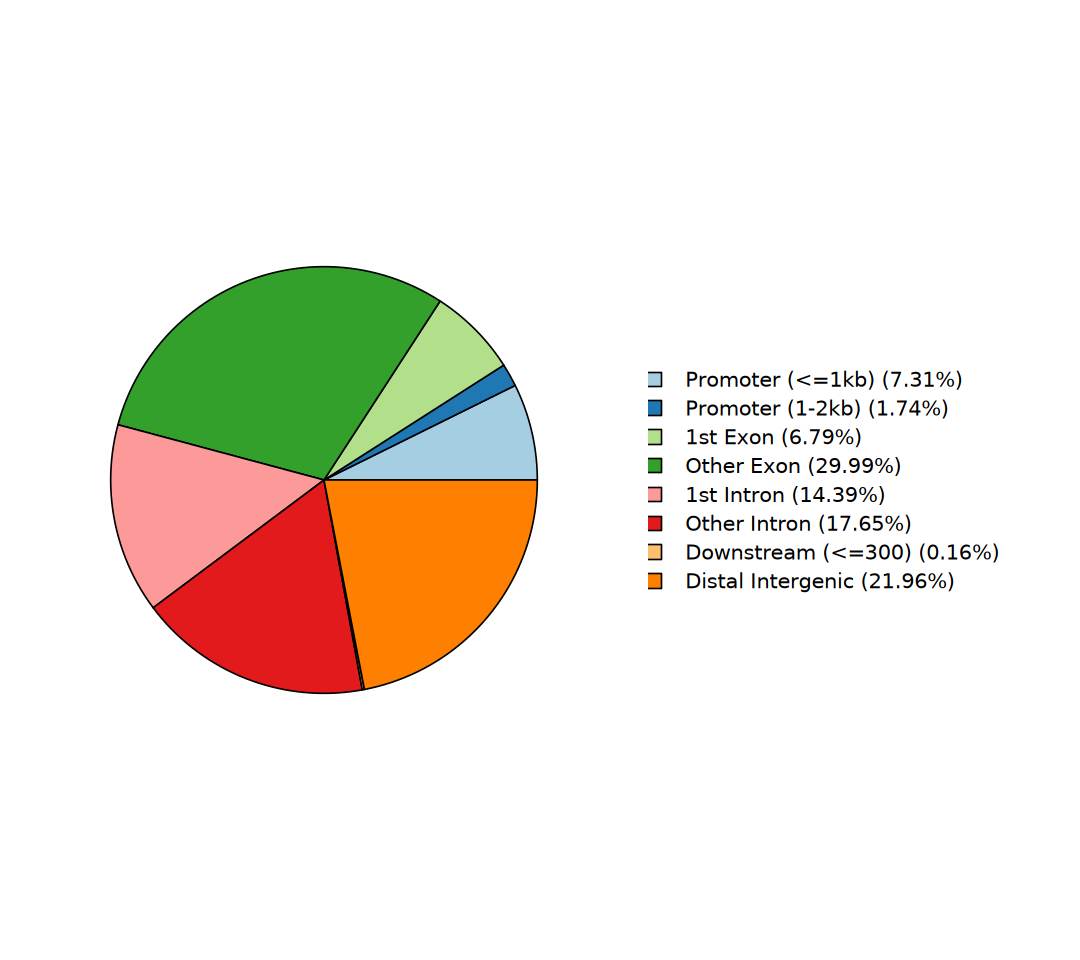

In [102]:
options(repr.plot.width = 9, repr.plot.height = 8)

plotAnnoPie(diff_dmrs_df, cex = 1)

In [103]:
diff_dmrs_anno <- diff_dmrs_df@anno

head(diff_dmrs_anno)

GRanges object with 6 ranges and 20 metadata columns:
        seqnames              ranges strand |  idxStart    idxEnd   cluster
           <Rle>           <IRanges>  <Rle> | <integer> <integer> <numeric>
  59085     chr1 186966336-186968709      * |   1301868   1301993    167119
  96066    chr18   36991608-36994788      * |  18069267  18069394    957366
  65034     chr4   12112810-12114342      * |   3975525   3975589   1347991
  94557    chr17   34904736-34907395      * |  17341280  17341371    875026
  87529    chr13   48490053-48491642      * |  14091925  14091978    514891
  67652     chr4 147219256-147220364      * |   5010997   5011060   1461501
                n invdensity  areaStat   maxStat  meanDiff group1.mean
        <integer>  <numeric> <numeric> <numeric> <numeric>   <numeric>
  59085       126    18.8413  -231.681 -0.786115 -0.202549    0.340501
  96066       128    24.8516  -217.797 -0.797016 -0.208366    0.507806
  65034        65    23.5846  -194.706 -0.911283 -0.28

In [104]:
gene_map <- bitr(
    diff_dmrs_anno$geneId, OrgDb = org.Mm.eg.db, drop = FALSE, 
    fromType = "ENTREZID", toType = "SYMBOL")

head(gene_map)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(diff_dmrs_anno$geneId, OrgDb = org.Mm.eg.db, drop = FALSE, :
“0.04% of input gene IDs are fail to map...”


,ENTREZID,SYMBOL
,<chr>,<chr>
1,110957,D1Pas1
2,353235,Pcdha8
3,329795,Tmem67
4,110147,Ehmt2
5,67911,Zfp169
6,71270,4933438K21Rik


In [105]:
mcols(diff_dmrs_anno)$geneSymbol <- gene_map$SYMBOL[
    match(diff_dmrs_anno$geneId, gene_map$ENTREZID)
]

In [108]:
gene_list <- diff_dmrs_anno |> mcols() |> as.data.frame() |>
    dplyr::filter(!is.na(geneId), geneId != "") |>
    dplyr::filter(str_detect(annotation, "Promoter")) |>
    dplyr::select(direction, geneId, geneSymbol) |>
    distinct(direction, geneId, geneSymbol)

gene_entrez <- split(gene_list$geneId, gene_list$direction)

In [110]:
ego_compare <- compareCluster(
    geneCluster = gene_entrez, fun = enrichGO, 
    universe = unique(GENES$gene_id), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'ENTREZID', pAdjustMethod = "BH", 
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

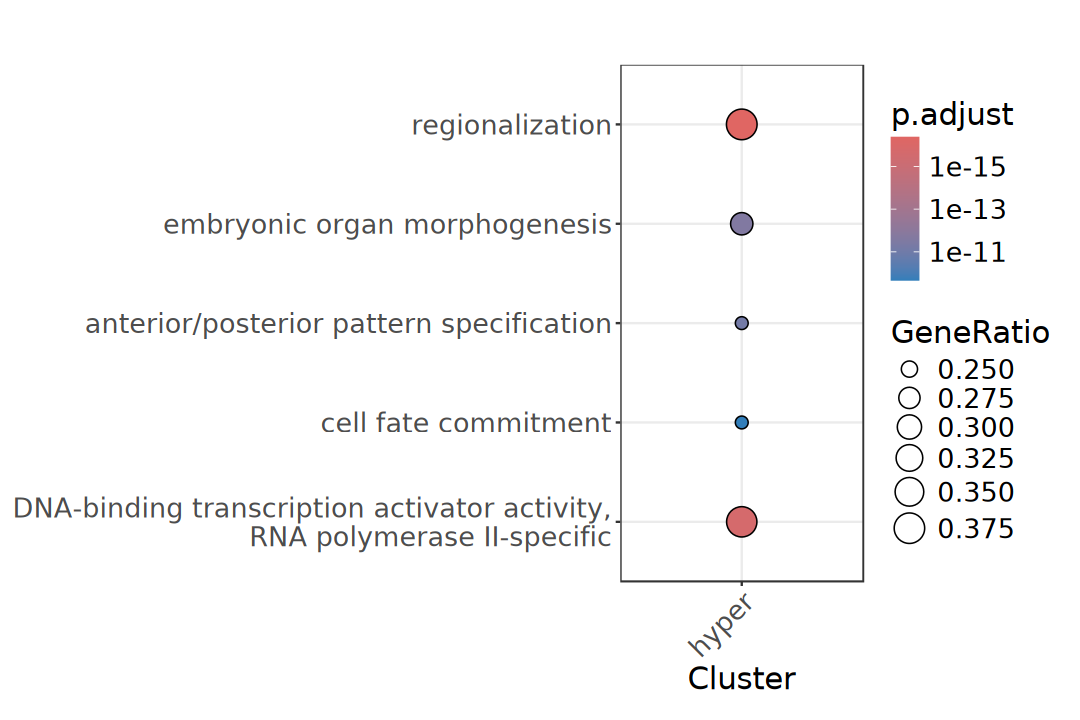

In [111]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

In [112]:
ekegg_compare <- compareCluster(
    geneCluster = gene_entrez, fun = enrichKEGG, 
    universe = unique(GENES$gene_id), 
    organism = "mmu", pAdjustMethod = "BH", 
    pvalueCutoff = 1, qvalueCutoff = 1, 
    minGSSize = 10, maxGSSize = 500)

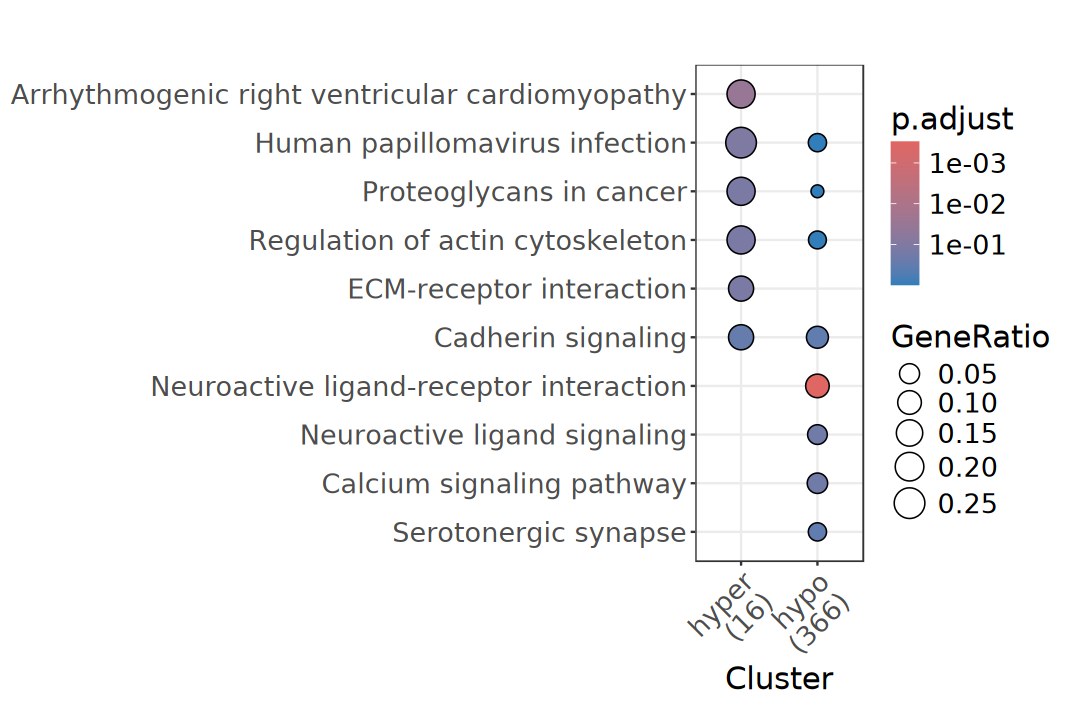

In [113]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

# 7. DMRs Visualization

In [114]:
table(diff_dmrs_anno$geneSymbol) |> 
    sort(decreasing = TRUE) |> head()


  Tiam1   Ark2c    Bcor Gm13090   Ajap1   Esrrb 
     20      13      13      13      12      11 

## IGV snapshot

In [118]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [119]:
genome_id = "mm10"
gene_id = "Esrrb"

entrez_id <- AnnotationDbi::mapIds(
    org.Mm.eg.db, keys = gene_id, keytype = "SYMBOL", column = "ENTREZID", 
    multiVals = "first")

entrez_id

loci <- GENES[GENES$gene_id == entrez_id]
loci <- resize(loci, width = width(loci) + 10000, fix = "center") |>
    trim()
target_region <- paste0(seqnames(loci), ":", start(loci), "-", end(loci))

target_region

'select()' returned 1:1 mapping between keys and columns



Esrrb 
"26380"

[1] "chr12:86356117-86526628"

In [120]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), 
        end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr12:86356117-86526628,chr12,86356117,86526628


In [121]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [122]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [123]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome_id, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 16, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [124]:
signal_colors <- colorRampPalette(brewer.pal(8, "Set2"))(length(meth_list))
names(signal_colors) <- names(meth_list)

In [125]:
signal_tracks <- purrr::imap(
    meth_list, ~ Gviz::DataTrack(
        range = .x, name = .y, data = "meth", type = "histogram",
        chromosome = target_region$chr, genome = genome_id,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = signal_colors[.y],
        fill.histogram = signal_colors[.y])
)

In [132]:
dmr_colors <- c(hyper = "#D73027", hypo  = "#1A9850")
diff_dmrs_anno$color <- dmr_colors[as.character(diff_dmrs_anno$direction)]

In [133]:
dmr_region <- subsetByOverlaps(diff_dmrs_anno, loci, ignore.strand = TRUE)
dmr_track <- Gviz::AnnotationTrack(
    range = dmr_region, name = "DMRs", genome = genome_id,
    chromosome = target_region$chr, type = "p", 
    fill = dmr_region$color, col = dmr_region$color,
    stacking = "squish", showTitle = TRUE, fontsize = 16, 
    cex.title = 1, cex.axis = 0.8, col.title = "black", 
    fontcolor.title = "black")

In [134]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome_id, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 18, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

# gene_info <- filter(GENES, type == "gene")

# ranges(grtrack)$symbol <- gene_info$gene_name[
#     match(ranges(grtrack)$gene, gene_info$gene_id)]

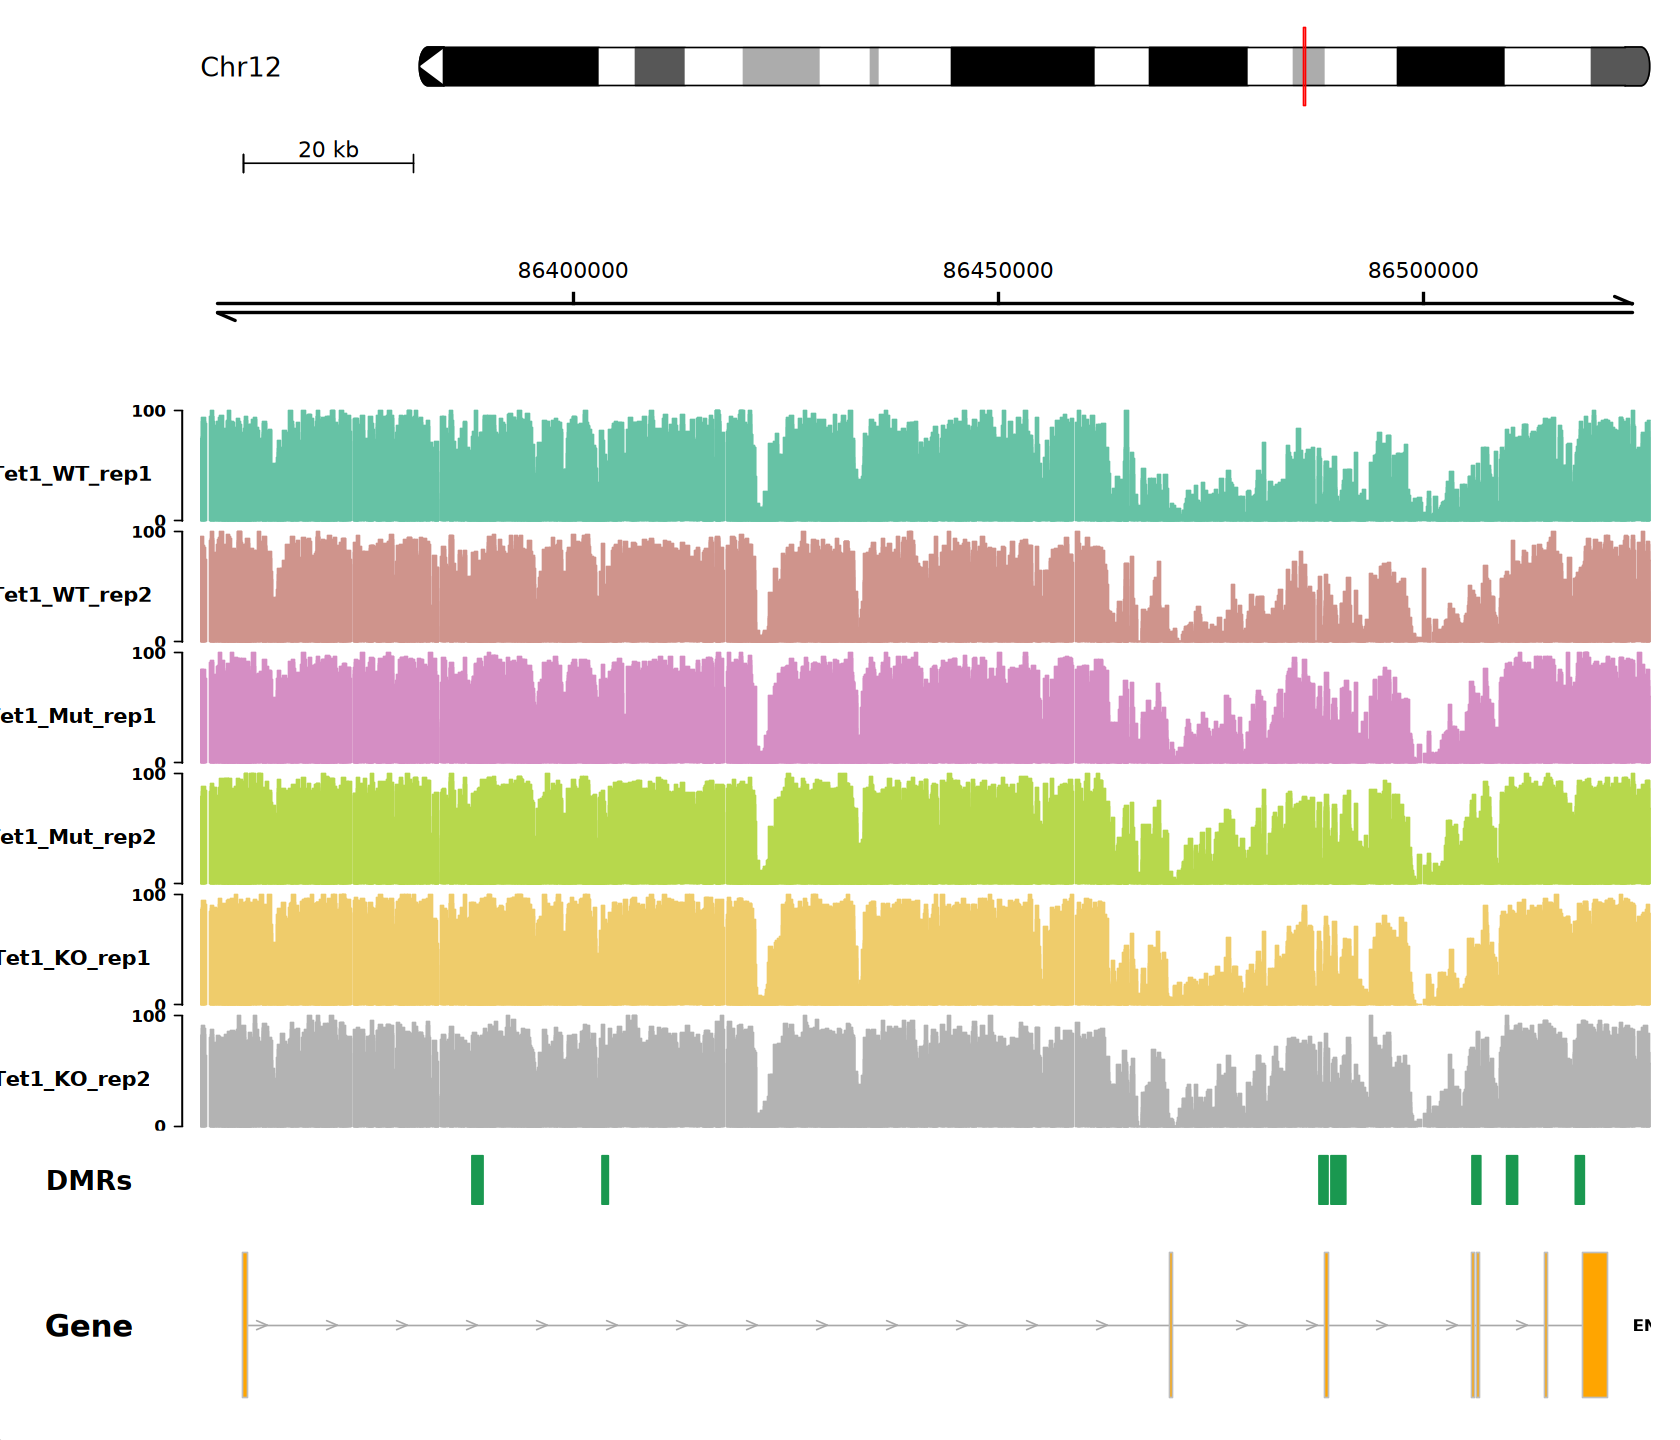

In [135]:
options(repr.plot.width = 14, repr.plot.height = 12)

plotTracks(
    trackList = c(plot_list, signal_tracks, dmr_track, grtrack), 
    chromosome = target_region$chr, 
    from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(meth_list)), 2, 4), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 1, 
    just.group = "right", extend.left = 0, 
    ylim = c(0, 100), yTicksAt = c(0, 100))

# * Reference